# D2C Customer Churn — Part 1: Data Audit, EDA & Business Understanding

**Snapshot date:** `2025-09-30`  
**Churn window:** `2025-10-01` → `2025-11-29` (60 days)  
**Target:** `churn_next_60d` — 1 if no purchase in the window, 0 otherwise  

---
### Notebook Structure
1. Setup & Imports  
2. Data Loading & Schema Inspection  
3. Data Quality Audit  
4. Exploratory Data Analysis  
   * 4.1 Customer Demographics  
   * 4.2 Order & Monetary Behaviour  
   * 4.3 Support Tickets  
   * 4.4 Web / App Activity  
   * 4.5 Campaign / Intervention History  
   * 4.6 Churn Distribution  
5. Churn-Risk Hypotheses (with evidence)  
6. Key Takeaways

## 1. Setup & Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import os

# ── Display settings ──────────────────────────────────────────────────────────
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 80)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.width', 120)

# ── Plot style ────────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
PALETTE = {'churned': '#e74c3c', 'retained': '#2ecc71'}
CHURN_PALETTE = {1: '#e74c3c', 0: '#2ecc71'}
FIG_DPI = 130

SNAPSHOT = pd.Timestamp('2025-09-30')

# ── Data path ─────────────────────────────────────────────────────────────────
from pathlib import Path

PROJECT_ROOT = Path.cwd()

# If notebook is executed from notebooks/01_eda
if PROJECT_ROOT.name == "01_eda":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data directory not found: {DATA_DIR}\n"
        f"Expected project root: {PROJECT_ROOT}"
    )

# print("Project root:", PROJECT_ROOT)
# print("Data directory:", DATA_DIR)

# ── Output path ─────────────────────────────────────────────────────────────────
EDA_OUTPUT_DIR = os.path.join(PROJECT_ROOT, "outputs", "eda")
EDA_CHARTS_DIR = os.path.join(EDA_OUTPUT_DIR, "charts")
os.makedirs(EDA_CHARTS_DIR, exist_ok=True)

def load(filename):
    return pd.read_csv(os.path.join(DATA_DIR, filename))

print('Libraries loaded. Snapshot date:', SNAPSHOT.date())

Libraries loaded. Snapshot date: 2025-09-30


## 2. Data Loading & Schema Inspection

In [2]:
customers    = load('customers.csv')
orders       = load('orders.csv')
tickets      = load('support_tickets.csv')
web          = load('web_events_snapshot.csv')
labels       = load('churn_labels.csv')
interventions= load('intervention_history.csv')

# Convert date columns
customers['signup_date']  = pd.to_datetime(customers['signup_date'])
orders['order_date']      = pd.to_datetime(orders['order_date'])
tickets['ticket_date']    = pd.to_datetime(tickets['ticket_date'])
web['snapshot_date']      = pd.to_datetime(web['snapshot_date'])
labels['snapshot_date']   = pd.to_datetime(labels['snapshot_date'])
interventions['snapshot_date'] = pd.to_datetime(interventions['snapshot_date'])

datasets = {
    'customers':     customers,
    'orders':        orders,
    'tickets':       tickets,
    'web_events':    web,
    'churn_labels':  labels,
    'interventions': interventions,
}

print(f"{'Dataset':<20} {'Rows':>8} {'Cols':>6}")
print('-' * 38)
for name, df in datasets.items():
    print(f"{name:<20} {df.shape[0]:>8,} {df.shape[1]:>6}")

Dataset                  Rows   Cols
--------------------------------------
customers               2,400      9
orders                 10,009     10
tickets                 1,921      8
web_events              2,400     10
churn_labels            2,400      4
interventions           2,400      5


In [3]:
# ── Schema snapshot for each file ─────────────────────────────────────────────
for name, df in datasets.items():
    print(f'\n{'='*60}')
    print(f'  {name.upper()}')
    print(f'{'='*60}')
    info = pd.DataFrame({
        'dtype': df.dtypes,
        'null_count': df.isna().sum(),
        'null_pct': (df.isna().mean() * 100).round(2),
        'n_unique': df.nunique()
    })
    print(info.to_string())


  CUSTOMERS
                              dtype  null_count  null_pct  n_unique
customer_id                     str           0    0.0000      2400
signup_date          datetime64[us]           0    0.0000       609
city_tier                       str           0    0.0000         3
age_group                       str           0    0.0000         4
acquisition_channel             str           0    0.0000         6
loyalty_tier                    str        1386   57.7500         3
preferred_category              str           0    0.0000         6
skin_type                       str         401   16.7100         5
marketing_consent               str           0    0.0000         2

  ORDERS
                        dtype  null_count  null_pct  n_unique
order_id                  str           0    0.0000     10009
customer_id               str           0    0.0000      2400
order_date     datetime64[us]           0    0.0000       674
category                  str           0    0.00

## 3. Data Quality Audit

> This section systematically checks for missing values, duplicates, outliers, date consistency, join integrity, and leakage risk.

### 3.1 Missing Values

In [4]:
print('── Missing Values Summary ──────────────────────────────────')
for name, df in datasets.items():
    miss = df.isna().sum()
    miss = miss[miss > 0]
    if len(miss):
        print(f'\n{name}:')
        for col, cnt in miss.items():
            print(f'  {col:<35} {cnt:>5} ({cnt/len(df)*100:.1f}%)')

# Focus: loyalty_tier missingness vs churn
lbl = labels[['customer_id','churn_next_60d']]
cust_lbl = customers.merge(lbl, on='customer_id')
loyalty_miss_churn = cust_lbl.groupby(cust_lbl['loyalty_tier'].isna())['churn_next_60d'].mean()
loyalty_miss_churn.index = ['Loyalty enrolled', 'Loyalty missing (not enrolled)']
print('\n── Churn rate by loyalty enrolment status ──────────────────')
print(loyalty_miss_churn.rename('churn_rate').to_string())

── Missing Values Summary ──────────────────────────────────

customers:
  loyalty_tier                         1386 (57.8%)
  skin_type                             401 (16.7%)

orders:
  rating                                 80 (0.8%)

── Churn rate by loyalty enrolment status ──────────────────
Loyalty enrolled                 0.4507
Loyalty missing (not enrolled)   0.4834


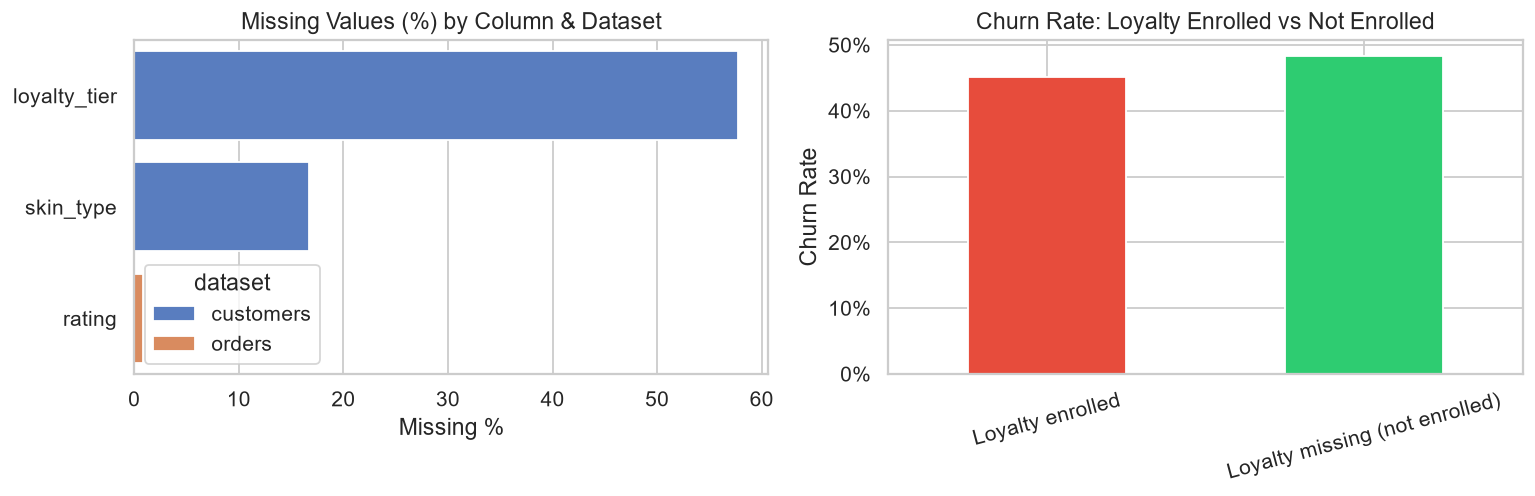

Saved: chart_01_missing_values.png


In [5]:
import os

# Visualise missing-value heatmap for customers
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=FIG_DPI)

# Missing by column across all datasets
miss_summary = []
for name, df in datasets.items():
    for col in df.columns:
        cnt = df[col].isna().sum()
        if cnt > 0:
            miss_summary.append({'dataset': name, 'column': col, 'missing_pct': cnt / len(df) * 100})

miss_df = pd.DataFrame(miss_summary)
sns.barplot(data=miss_df, y='column', x='missing_pct', hue='dataset', ax=axes[0], orient='h')
axes[0].set_title('Missing Values (%) by Column & Dataset')
axes[0].set_xlabel('Missing %')
axes[0].set_ylabel('')

# Churn rate: loyalty enrolled vs not
colors = [PALETTE['retained'], PALETTE['churned']]
loyalty_miss_churn.plot(kind='bar', color=colors[::-1], ax=axes[1], rot=15)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title('Churn Rate: Loyalty Enrolled vs Not Enrolled')
axes[1].set_ylabel('Churn Rate')
axes[1].set_xlabel('')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_01_missing_values.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_01_missing_values.png')

### 3.2 Duplicate Records

In [6]:
# ── Customer-level duplicates ─────────────────────────────────────────────────
print('Duplicate customer_id rows in customers:', customers.duplicated('customer_id').sum())

# ── Order-level: _DUP suffix ─────────────────────────────────────────────────
dup_orders = orders[orders['order_id'].str.endswith('_DUP')]
print(f'\nOrders with _DUP suffix: {len(dup_orders)} ({len(dup_orders)/len(orders)*100:.1f}%)')
print(dup_orders.head())

# Confirm: are they exact copies of non-DUP rows?
dup_orders_clean = dup_orders.copy()
dup_orders_clean['order_id'] = dup_orders_clean['order_id'].str.replace('_DUP', '', regex=False)
matched = dup_orders_clean.merge(
    orders[~orders['order_id'].str.endswith('_DUP')],
    on=['order_id','customer_id','order_date','gross_amount'],
    suffixes=('_dup','_orig')
)
print(f'\n_DUP rows that match an original row exactly: {len(matched)} / {len(dup_orders)}')

# ── Fully duplicate rows (all columns identical) ──────────────────────────────
for name, df in datasets.items():
    full_dups = df.duplicated().sum()
    if full_dups:
        print(f'\nFully duplicate rows in {name}: {full_dups}')

Duplicate customer_id rows in customers: 0

Orders with _DUP suffix: 12 (0.1%)
           order_id customer_id order_date   category  quantity  gross_amount  discount_pct  delivery_days  returned  \
601   ORD008249_DUP   CUST00153 2025-11-04  Hair Care         1      321.3100        0.3600              8         0   
2621  ORD002124_DUP   CUST00628 2025-03-18  Skin Care         1      410.0400        0.4700              3         0   
3534  ORD002862_DUP   CUST00837 2025-07-12  Hair Care         3      952.0200        0.4700              4         0   
3602  ORD002916_DUP   CUST00848 2025-09-26  Skin Care         1      547.1800        0.2800              2         0   
3675  ORD002970_DUP   CUST00869 2024-12-22  Fragrance         1      818.6400        0.1800              2         0   

      rating  
601   3.0000  
2621  5.0000  
3534  4.0000  
3602  5.0000  
3675  4.0000  

_DUP rows that match an original row exactly: 12 / 12


### 3.3 Outliers & Unusual Values — `orders.gross_amount`

In [7]:
pre_orders = orders[orders['order_date'] <= SNAPSHOT].copy()

q1  = pre_orders['gross_amount'].quantile(0.25)
q3  = pre_orders['gross_amount'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 3 * iqr

outliers = pre_orders[pre_orders['gross_amount'] > upper_fence]
print(f'IQR upper fence (Q3 + 3×IQR): ₹{upper_fence:,.0f}')
print(f'Outlier orders: {len(outliers)} ({len(outliers)/len(pre_orders)*100:.1f}%)')
print(f'\nOutlier gross_amount stats:')
print(outliers['gross_amount'].describe().to_string())

# discount_pct range check
print('\n── discount_pct outside [0,1]:', ((pre_orders['discount_pct'] < 0) | (pre_orders['discount_pct'] > 1)).sum())

# rating range check
print('── rating outside [1,5]:', ((orders['rating'] < 1) | (orders['rating'] > 5)).dropna().sum())

# delivery_days range check
print('── delivery_days < 1:', (pre_orders['delivery_days'] < 1).sum())
print('── delivery_days > 11:', (pre_orders['delivery_days'] > 11).sum())

IQR upper fence (Q3 + 3×IQR): ₹2,396
Outlier orders: 73 (0.9%)

Outlier gross_amount stats:
count      73.0000
mean     3702.0382
std      3950.6672
min      2397.5000
25%      2493.2700
50%      2659.6800
75%      2848.1800
max     24789.3800

── discount_pct outside [0,1]: 0
── rating outside [1,5]: 0
── delivery_days < 1: 0
── delivery_days > 11: 0


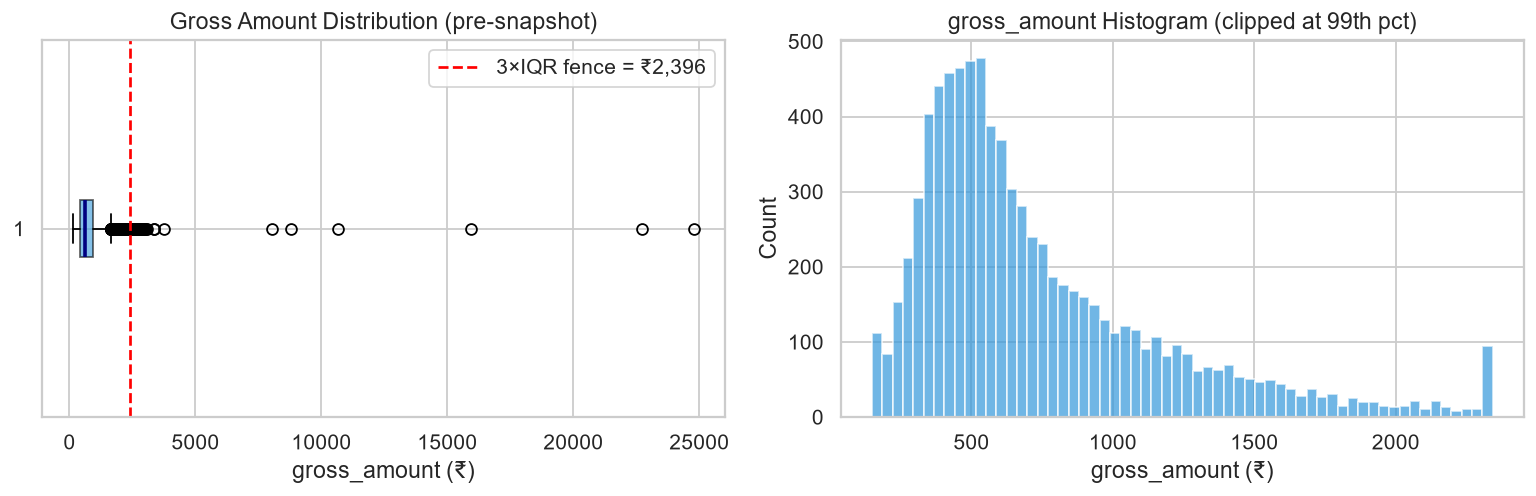

Saved: chart_02_gross_amount_outliers.png


In [8]:
import os

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=FIG_DPI)

# Box plot — gross_amount
axes[0].boxplot(pre_orders['gross_amount'], vert=False, patch_artist=True,
                boxprops=dict(facecolor='#3498db', alpha=0.6),
                medianprops=dict(color='navy', linewidth=2))
axes[0].axvline(upper_fence, color='red', linestyle='--', label=f'3×IQR fence = ₹{upper_fence:,.0f}')
axes[0].set_title('Gross Amount Distribution (pre-snapshot)')
axes[0].set_xlabel('gross_amount (₹)')
axes[0].legend()

# Histogram — gross_amount (clipped for readability)
clip_val = pre_orders['gross_amount'].quantile(0.99)
axes[1].hist(pre_orders['gross_amount'].clip(upper=clip_val), bins=60,
             color='#3498db', alpha=0.7, edgecolor='white')
axes[1].set_title('gross_amount Histogram (clipped at 99th pct)')
axes[1].set_xlabel('gross_amount (₹)')
axes[1].set_ylabel('Count')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_02_gross_amount_outliers.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_02_gross_amount_outliers.png')

### 3.4 Date Consistency & Post-Snapshot Leakage

In [9]:
post_orders = orders[orders['order_date'] > SNAPSHOT]
print(f'Post-snapshot orders (LEAKAGE RISK):  {len(post_orders):,} ({len(post_orders)/len(orders)*100:.1f}%)')
print(f'Pre-snapshot orders (safe to use):    {len(pre_orders):,}')

# signup_date range
print(f'\nsignup_date range: {customers["signup_date"].min().date()} → {customers["signup_date"].max().date()}')
late_signups = customers[customers['signup_date'] > SNAPSHOT]
print(f'Customers signed up after snapshot:  {len(late_signups)}')

# ticket_date range
print(f'ticket_date range: {tickets["ticket_date"].min().date()} → {tickets["ticket_date"].max().date()}')
post_tickets = tickets[tickets['ticket_date'] > SNAPSHOT]
print(f'Tickets after snapshot:              {len(post_tickets)}')

Post-snapshot orders (LEAKAGE RISK):  1,872 (18.7%)
Pre-snapshot orders (safe to use):    8,137

signup_date range: 2024-01-01 → 2025-09-15
Customers signed up after snapshot:  0
ticket_date range: 2024-01-13 → 2025-09-30
Tickets after snapshot:              0


### 3.5 Join Integrity

In [10]:
universe = set(customers['customer_id'])
print(f'Customer universe: {len(universe):,}')
print()

# Which customer_ids appear in each dataset?
for name, df in datasets.items():
    if 'customer_id' in df.columns:
        ids_in_file = set(df['customer_id'])
        in_univ  = ids_in_file & universe
        orphan   = ids_in_file - universe
        no_data  = universe - ids_in_file
        print(f'{name:<20} | IDs in file: {len(ids_in_file):,} | In universe: {len(in_univ):,} | Orphan (not in customers): {len(orphan):,} | Customers with no record: {len(no_data):,}')

# Customers with zero orders before snapshot
custs_with_pre_orders = set(pre_orders['customer_id'])
zero_order_custs = universe - custs_with_pre_orders
print(f'\nCustomers with ZERO pre-snapshot orders: {len(zero_order_custs)}')
# Check their churn labels
zero_churn = labels[labels['customer_id'].isin(zero_order_custs)]['churn_next_60d'].value_counts(normalize=True)
print(f'Churn rate among zero-order customers:\n{zero_churn.rename(index={1:"churned",0:"retained"}).to_string()}')

Customer universe: 2,400

customers            | IDs in file: 2,400 | In universe: 2,400 | Orphan (not in customers): 0 | Customers with no record: 0
orders               | IDs in file: 2,400 | In universe: 2,400 | Orphan (not in customers): 0 | Customers with no record: 0
tickets              | IDs in file: 1,247 | In universe: 1,247 | Orphan (not in customers): 0 | Customers with no record: 1,153
web_events           | IDs in file: 2,400 | In universe: 2,400 | Orphan (not in customers): 0 | Customers with no record: 0
churn_labels         | IDs in file: 2,400 | In universe: 2,400 | Orphan (not in customers): 0 | Customers with no record: 0
interventions        | IDs in file: 2,400 | In universe: 2,400 | Orphan (not in customers): 0 | Customers with no record: 0

Customers with ZERO pre-snapshot orders: 0
Churn rate among zero-order customers:
Series([], )


## 4. Exploratory Data Analysis

> All EDA is done at the **customer level**, merging with churn labels to reveal churn-relevant patterns.

In [11]:
# Build master analytical dataframe
# Start with labels as the spine
master = labels.merge(customers, on='customer_id', how='left')
master = master.merge(web.drop(columns=['snapshot_date']), on='customer_id', how='left')
master = master.merge(interventions.drop(columns=['snapshot_date']), on='customer_id', how='left')

# Pre-snapshot order aggregates (safe features)
pre_clean = pre_orders[~pre_orders['order_id'].str.endswith('_DUP')].copy()
order_agg = pre_clean.groupby('customer_id').agg(
    total_orders       = ('order_id', 'count'),
    recency_days       = ('order_date', lambda x: (SNAPSHOT - x.max()).days),
    total_spend        = ('gross_amount', 'sum'),
    avg_order_value    = ('gross_amount', 'mean'),
    return_rate        = ('returned', 'mean'),
    avg_discount       = ('discount_pct', 'mean'),
    avg_rating         = ('rating', 'mean'),
    category_diversity = ('category', 'nunique'),
).reset_index()
master = master.merge(order_agg, on='customer_id', how='left')

# Support ticket aggregates
ticket_agg = tickets.groupby('customer_id').agg(
    ticket_count       = ('ticket_id', 'count'),
    avg_sentiment      = ('sentiment_score', 'mean'),
    negative_ticket_rt = ('sentiment_score', lambda x: (x < 0).mean()),
    avg_resolution_hrs = ('resolution_hours', 'mean'),
    reopened_rate      = ('reopened', 'mean'),
).reset_index()
master = master.merge(ticket_agg, on='customer_id', how='left')
master['ticket_count'] = master['ticket_count'].fillna(0)
master['has_ticket'] = (master['ticket_count'] > 0).astype(int)

# Days since signup
master['days_since_signup'] = (SNAPSHOT - master['signup_date']).dt.days

print(f'Master dataframe shape: {master.shape}')
print(f'Churn rate overall: {master["churn_next_60d"].mean():.1%}')
master.head(3)

Master dataframe shape: (2400, 38)
Churn rate overall: 47.0%


,customer_id,snapshot_date,churn_next_60d,split,signup_date,city_tier,age_group,acquisition_channel,loyalty_tier,preferred_category,skin_type,marketing_consent,sessions_30d,product_views_30d,cart_adds_30d,wishlist_adds_30d,abandoned_carts_30d,email_opens_30d,campaign_clicks_30d,last_visit_days_ago,last_campaign_received,last_campaign_cost,manual_priority_bucket,total_orders,recency_days,total_spend,avg_order_value,return_rate,avg_discount,avg_rating,category_diversity,ticket_count,avg_sentiment,negative_ticket_rt,avg_resolution_hrs,reopened_rate,has_ticket,days_since_signup
0,CUST00001,2025-09-30,1,train,2024-04-24,Tier 1,18-24,Instagram,Silver,Makeup,Normal,Yes,1,4,0,0,0,2,0,20,welcome_offer,25,high,6,107,2955.5700,492.5950,0.1667,0.3633,3.3333,3,2.0000,0.1400,0.5000,4.3500,0.0000,1,524
1,CUST00002,2025-09-30,0,train,2025-06-01,Tier 2,25-34,Marketplace,Silver,Hair Care,Combination,Yes,8,31,4,2,3,0,0,0,free_shipping,12,medium,1,40,581.0000,581.0000,0.0000,0.2300,4.0000,1,1.0000,0.0000,0.0000,1.0000,0.0000,1,121
2,CUST00003,2025-09-30,1,train,2025-03-08,Tier 1,25-34,Influencer,NaN,Skin Care,Oily,Yes,1,3,0,0,0,0,0,26,none,18,high,1,171,649.9800,649.9800,0.0000,0.4700,2.0000,1,0.0000,NaN,NaN,NaN,NaN,0,206


### 4.1 Customer Demographics

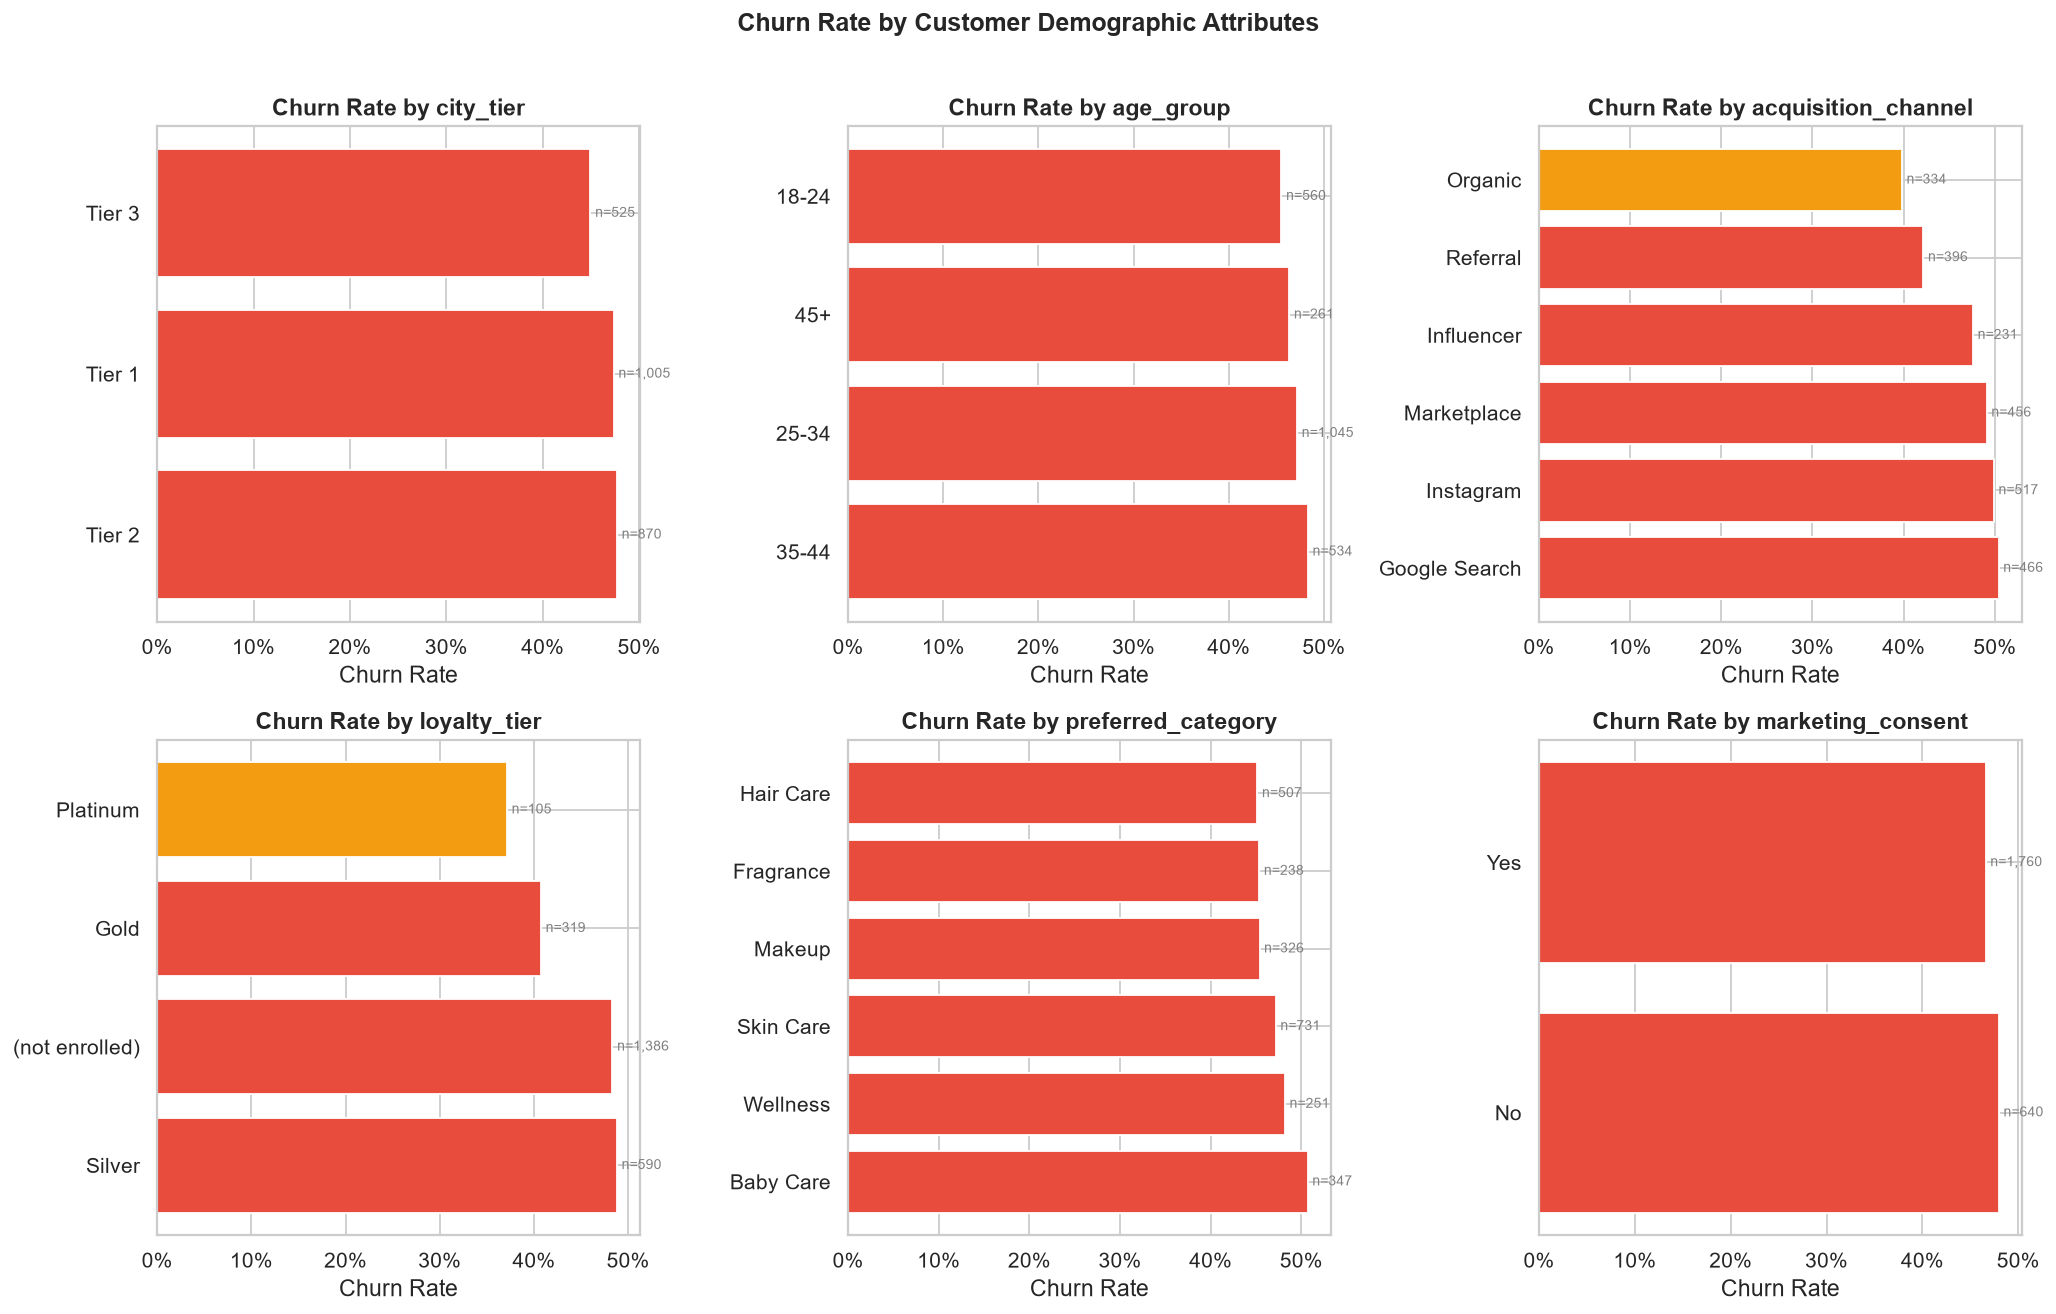

Saved: chart_03_demographics_churn.png


In [12]:
import os

fig, axes = plt.subplots(2, 3, figsize=(16, 10), dpi=FIG_DPI)
cat_cols = ['city_tier', 'age_group', 'acquisition_channel', 'loyalty_tier', 'preferred_category', 'marketing_consent']

for ax, col in zip(axes.flat, cat_cols):
    tbl = master.groupby(col, dropna=False)['churn_next_60d'].agg(['mean','count']).reset_index()
    tbl.columns = [col, 'churn_rate', 'count']
    tbl[col] = tbl[col].fillna('(not enrolled)')
    tbl = tbl.sort_values('churn_rate', ascending=False)
    colors = [PALETTE['churned'] if r > 0.4 else PALETTE['retained'] if r < 0.25 else '#f39c12'
              for r in tbl['churn_rate']]
    bars = ax.barh(tbl[col].astype(str), tbl['churn_rate'], color=colors)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(f'Churn Rate by {col}', fontweight='bold')
    ax.set_xlabel('Churn Rate')
    # Annotate with count
    for bar, n in zip(bars, tbl['count']):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f'n={n:,}', va='center', fontsize=8, color='grey')

plt.suptitle('Churn Rate by Customer Demographic Attributes', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_03_demographics_churn.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_03_demographics_churn.png')

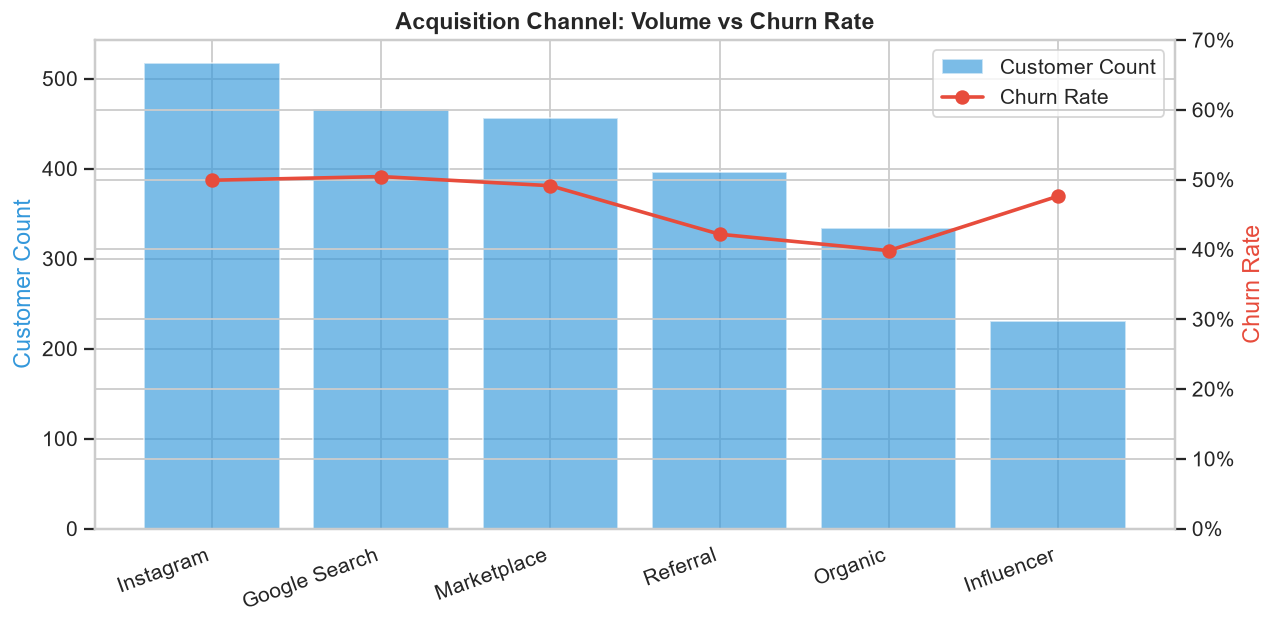

Saved: chart_04_acquisition_channel.png


In [13]:
import os

# Acquisition channel volume + churn rate dual-axis
acq = master.groupby('acquisition_channel').agg(
    count=('customer_id','count'),
    churn_rate=('churn_next_60d','mean')
).sort_values('count', ascending=False).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5), dpi=FIG_DPI)
ax2 = ax1.twinx()
x = range(len(acq))
ax1.bar(x, acq['count'], color='#3498db', alpha=0.65, label='Customer Count')
ax2.plot(x, acq['churn_rate'], 'o-', color='#e74c3c', lw=2, ms=7, label='Churn Rate')
ax1.set_xticks(list(x))
ax1.set_xticklabels(acq['acquisition_channel'], rotation=20, ha='right')
ax1.set_ylabel('Customer Count', color='#3498db')
ax2.set_ylabel('Churn Rate', color='#e74c3c')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set_ylim(0, 0.7)
ax1.set_title('Acquisition Channel: Volume vs Churn Rate', fontweight='bold')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_04_acquisition_channel.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_04_acquisition_channel.png')

### 4.2 Order & Monetary Behaviour

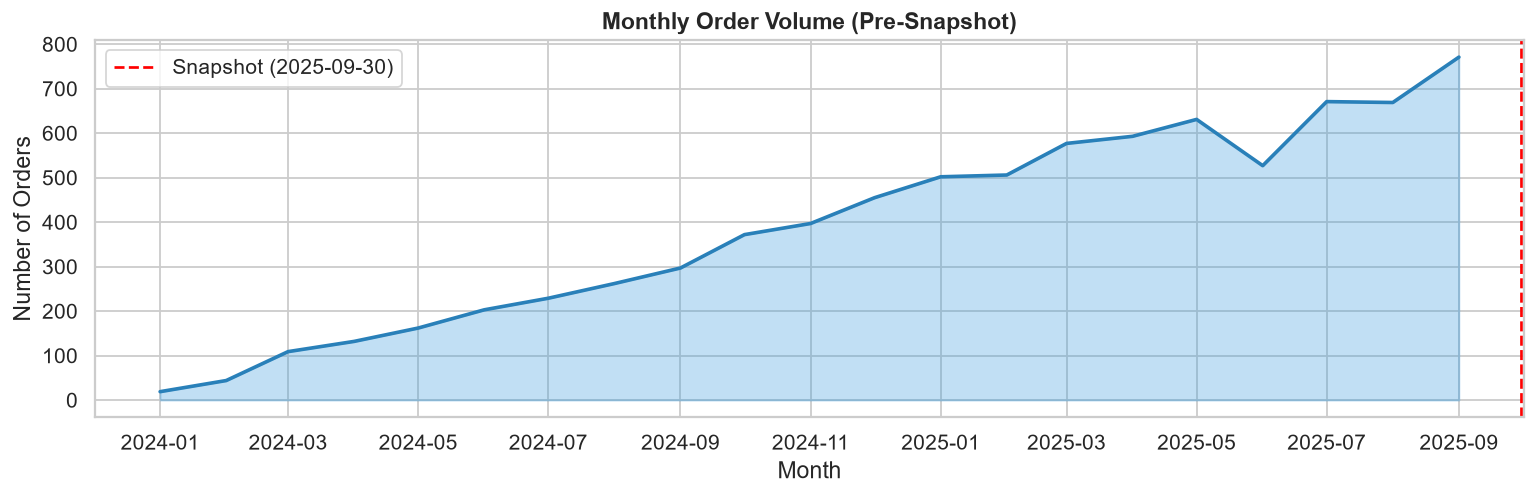

Saved: chart_05_monthly_orders.png


In [14]:
import os

# Monthly order volume over time
pre_clean['month'] = pre_clean['order_date'].dt.to_period('M')
monthly = pre_clean.groupby('month').size().reset_index(name='order_count')
monthly['month_dt'] = monthly['month'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4), dpi=FIG_DPI)
ax.fill_between(monthly['month_dt'], monthly['order_count'], alpha=0.3, color='#3498db')
ax.plot(monthly['month_dt'], monthly['order_count'], color='#2980b9', lw=2)
ax.axvline(SNAPSHOT, color='red', linestyle='--', lw=1.5, label='Snapshot (2025-09-30)')
ax.set_title('Monthly Order Volume (Pre-Snapshot)', fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Number of Orders')
ax.legend()
plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_05_monthly_orders.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_05_monthly_orders.png')

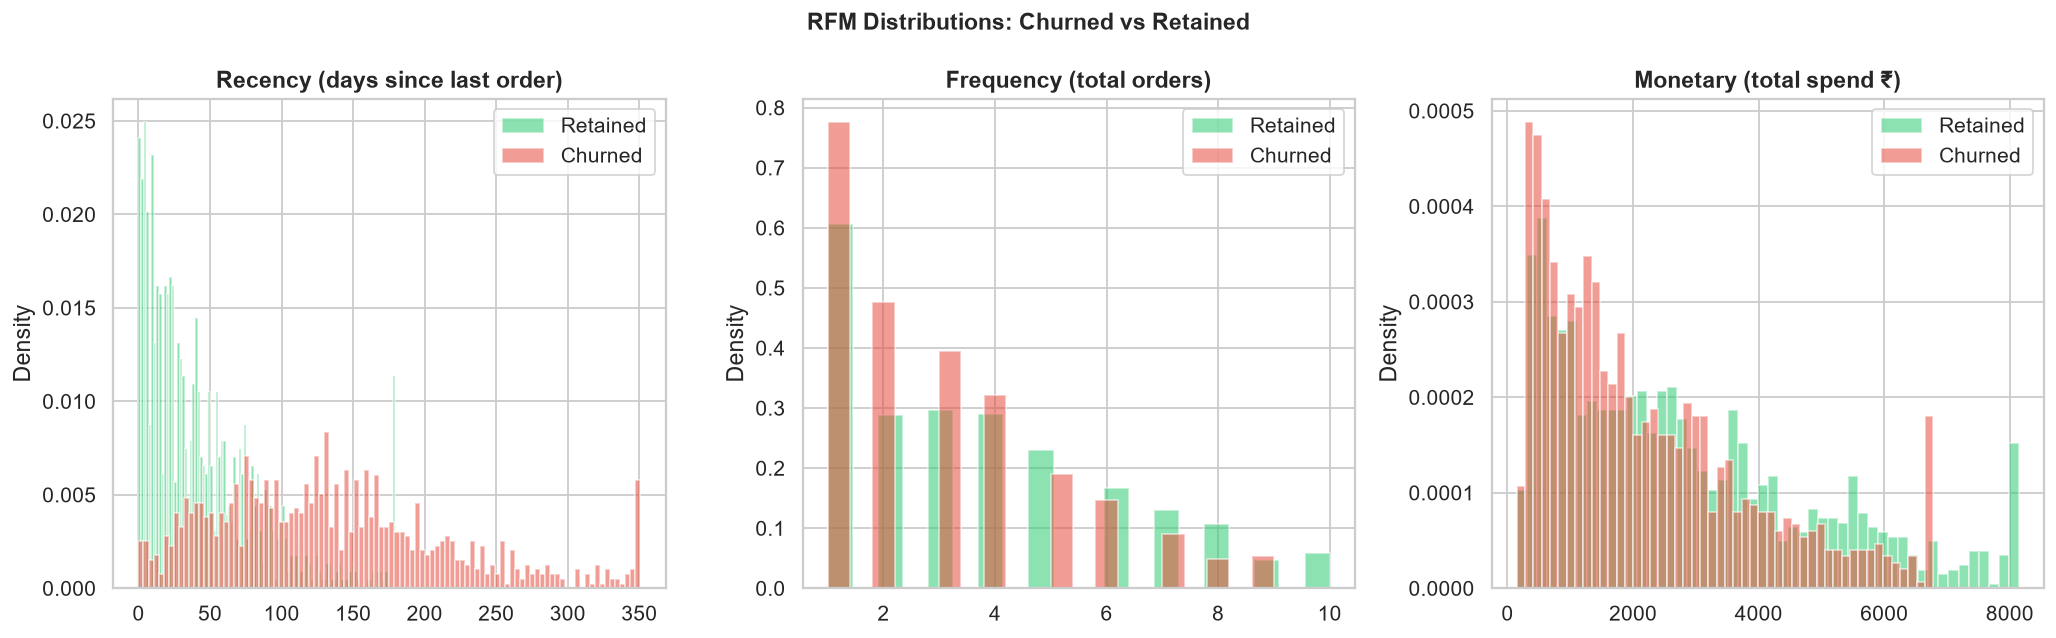

Saved: chart_06_rfm_distributions.png


In [15]:
import os

# Recency, frequency, monetary distributions by churn status
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=FIG_DPI)

rfm_metrics = [
    ('recency_days',    'Recency (days since last order)',   100),
    ('total_orders',    'Frequency (total orders)',          20),
    ('total_spend',     'Monetary (total spend ₹)',          50),
]

for ax, (col, title, bins) in zip(axes, rfm_metrics):
    for churn_val, label, color in [(0, 'Retained', '#2ecc71'), (1, 'Churned', '#e74c3c')]:
        subset = master[master['churn_next_60d'] == churn_val][col].dropna()
        ax.hist(subset.clip(upper=subset.quantile(0.98)), bins=bins,
                alpha=0.55, label=label, color=color, density=True)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('RFM Distributions: Churned vs Retained', fontsize=13, fontweight='bold')
plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_06_rfm_distributions.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_06_rfm_distributions.png')

In [16]:
# Average order stats by churn status
rfm_summary = master.groupby('churn_next_60d').agg(
    avg_recency       = ('recency_days','mean'),
    avg_frequency     = ('total_orders','mean'),
    avg_monetary      = ('total_spend','mean'),
    avg_order_value   = ('avg_order_value','mean'),
    avg_return_rate   = ('return_rate','mean'),
    avg_discount_pct  = ('avg_discount','mean'),
    avg_rating        = ('avg_rating','mean'),
    cat_diversity     = ('category_diversity','mean'),
).rename(index={0:'Retained', 1:'Churned'})
print('── RFM & Order Behaviour by Churn Status ────────────────────')
print(rfm_summary.T.to_string())

# Statistical tests
print('\n── Mann-Whitney U tests (churned vs retained) ───────────────')
for col in ['recency_days','total_orders','total_spend','return_rate','avg_discount']:
    churn1 = master[master['churn_next_60d']==1][col].dropna()
    churn0 = master[master['churn_next_60d']==0][col].dropna()
    u, p = stats.mannwhitneyu(churn1, churn0, alternative='two-sided')
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else '(ns)'
    print(f'  {col:<25} p={p:.4f} {sig}')

── RFM & Order Behaviour by Churn Status ────────────────────
churn_next_60d    Retained   Churned
avg_recency        45.0746  135.1571
avg_frequency       3.6984    3.0346
avg_monetary     2835.2593 2221.6462
avg_order_value   771.6136  733.2479
avg_return_rate     0.0549    0.0824
avg_discount_pct    0.2768    0.2851
avg_rating          3.9192    3.8628
cat_diversity       2.4737    2.2130

── Mann-Whitney U tests (churned vs retained) ───────────────
  recency_days              p=0.0000 ***
  total_orders              p=0.0000 ***
  total_spend               p=0.0000 ***
  return_rate               p=0.5384 (ns)
  avg_discount              p=0.0488 *


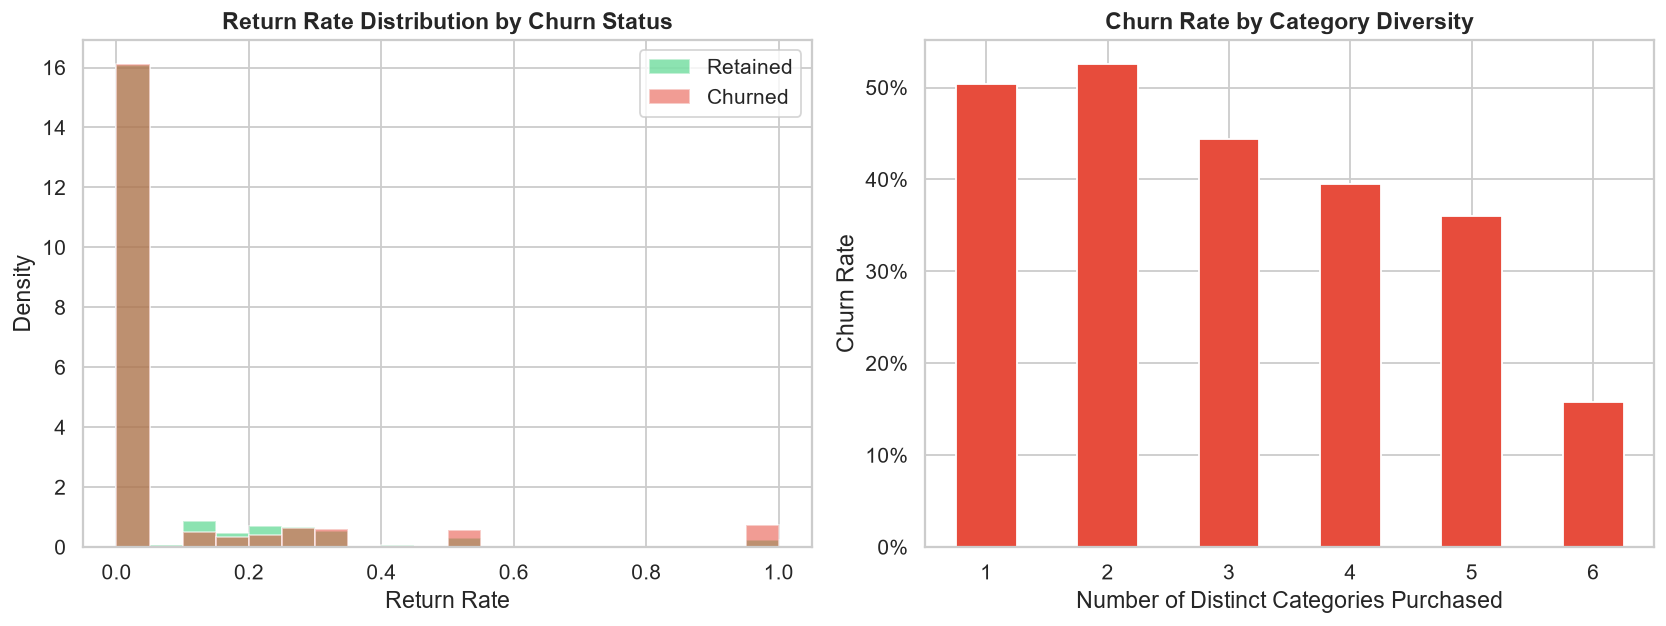

Saved: chart_07_return_category.png


In [17]:
import os

# Return rate and category diversity vs churn
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=FIG_DPI)

# Return rate by churn
for churn_val, label, color in [(0,'Retained','#2ecc71'),(1,'Churned','#e74c3c')]:
    sub = master[master['churn_next_60d']==churn_val]['return_rate'].dropna()
    axes[0].hist(sub, bins=20, alpha=0.55, label=label, color=color, density=True)
axes[0].set_title('Return Rate Distribution by Churn Status', fontweight='bold')
axes[0].set_xlabel('Return Rate')
axes[0].set_ylabel('Density')
axes[0].legend()

# Category diversity
cat_div = master.groupby(['category_diversity','churn_next_60d']).size().unstack(fill_value=0)
cat_div_rate = cat_div[1] / (cat_div[0] + cat_div[1])
cat_div_rate.plot(kind='bar', color='#e74c3c', ax=axes[1], rot=0)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title('Churn Rate by Category Diversity', fontweight='bold')
axes[1].set_xlabel('Number of Distinct Categories Purchased')
axes[1].set_ylabel('Churn Rate')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_07_return_category.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_07_return_category.png')

### 4.3 Support Ticket Analysis

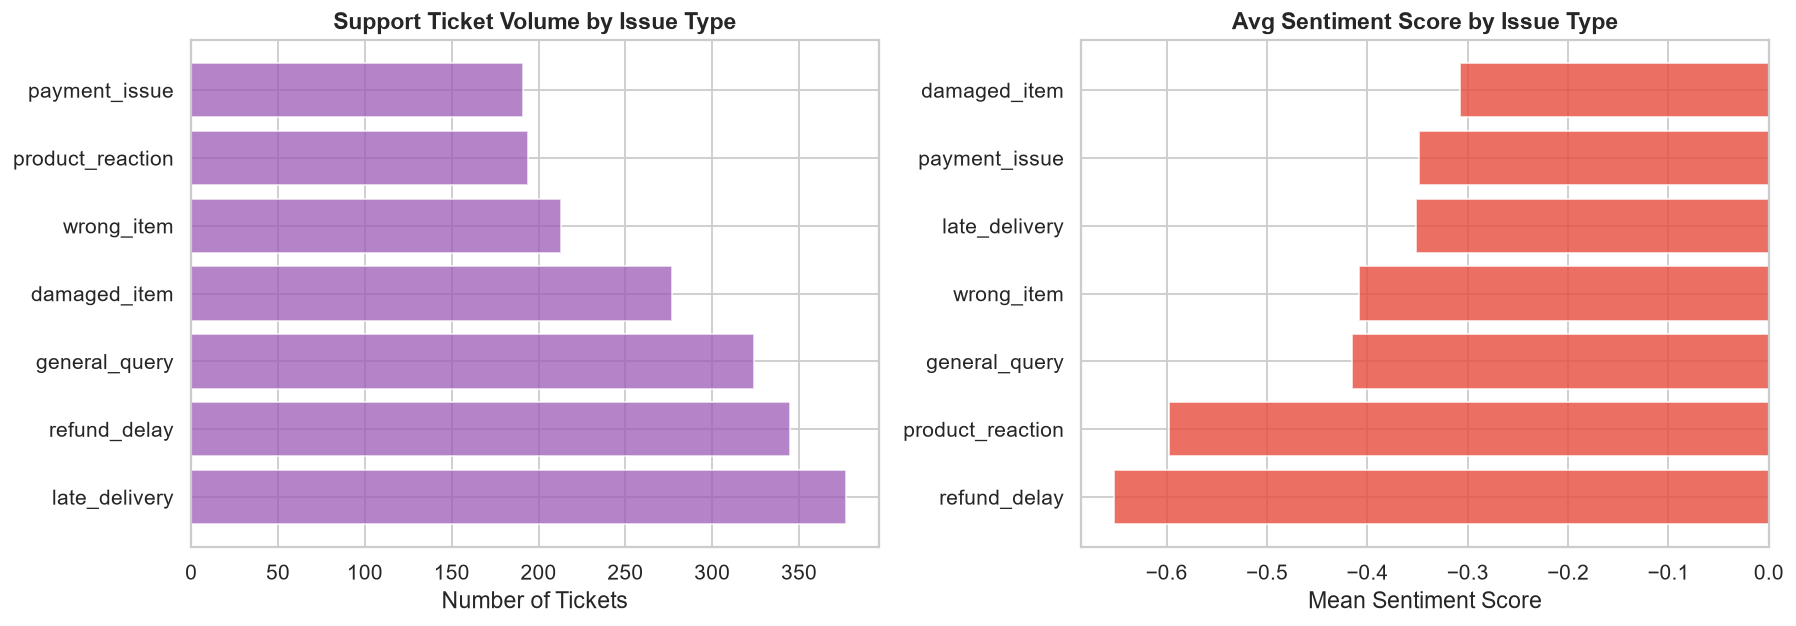

Saved: chart_08_support_tickets.png


In [18]:
import os

# Issue type frequency
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=FIG_DPI)

issue_freq = tickets['issue_type'].value_counts()
axes[0].barh(issue_freq.index, issue_freq.values, color='#9b59b6', alpha=0.75)
axes[0].set_title('Support Ticket Volume by Issue Type', fontweight='bold')
axes[0].set_xlabel('Number of Tickets')

# Average sentiment by issue type
issue_sentiment = tickets.groupby('issue_type')['sentiment_score'].mean().sort_values()
colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in issue_sentiment.values]
axes[1].barh(issue_sentiment.index, issue_sentiment.values, color=colors, alpha=0.8)
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_title('Avg Sentiment Score by Issue Type', fontweight='bold')
axes[1].set_xlabel('Mean Sentiment Score')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_08_support_tickets.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_08_support_tickets.png')

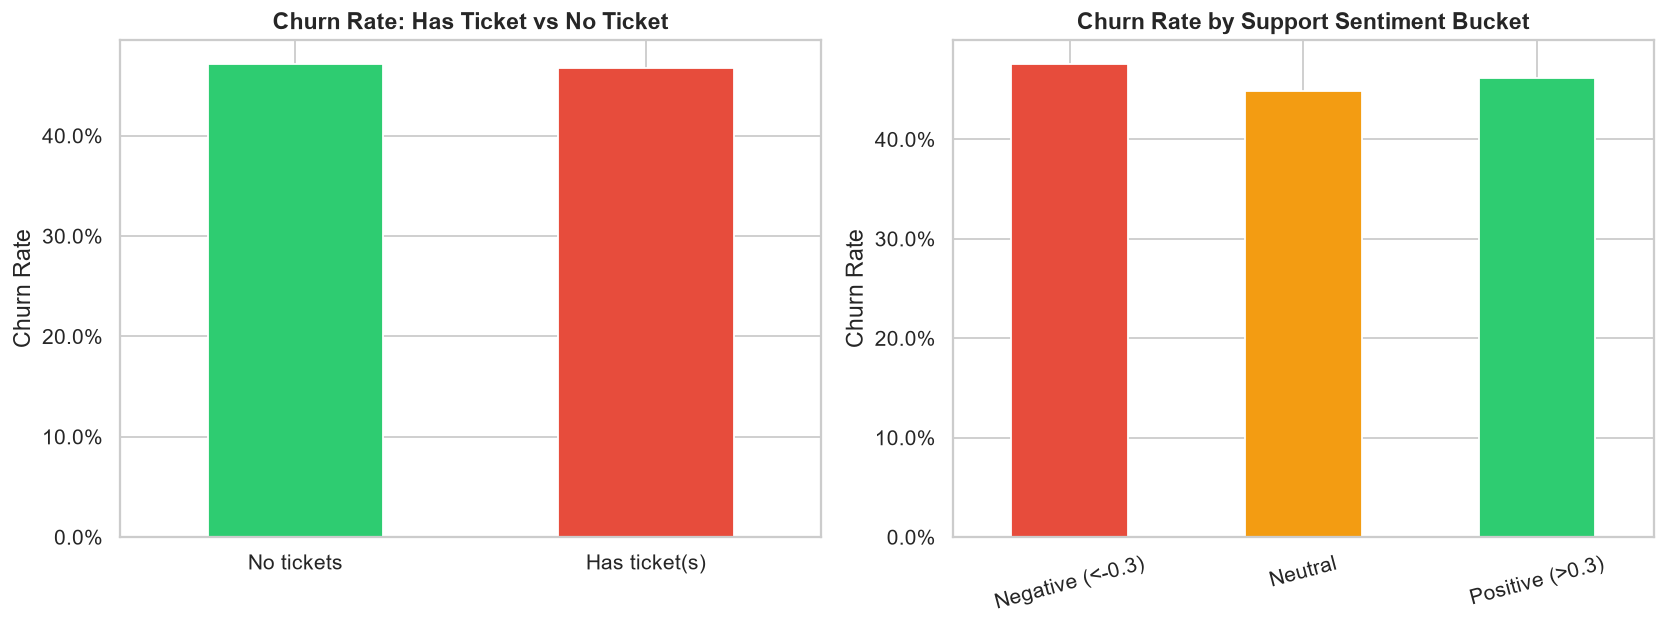

Saved: chart_09_ticket_sentiment_churn.png


In [19]:
import os

# Churn rate by support ticket presence and sentiment bucket
master['sentiment_bucket'] = pd.cut(
    master['avg_sentiment'],
    bins=[-1.1, -0.3, 0.3, 1.1],
    labels=['Negative (<-0.3)', 'Neutral', 'Positive (>0.3)']
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=FIG_DPI)

# Churn rate: has ticket vs no ticket
ticket_churn = master.groupby('has_ticket')['churn_next_60d'].mean()
ticket_churn.index = ['No tickets', 'Has ticket(s)']
ticket_churn.plot(kind='bar', color=[PALETTE['retained'], PALETTE['churned']], ax=axes[0], rot=0)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title('Churn Rate: Has Ticket vs No Ticket', fontweight='bold')
axes[0].set_ylabel('Churn Rate')
axes[0].set_xlabel('')

# Churn rate by sentiment bucket
sent_churn = master.groupby('sentiment_bucket', observed=True)['churn_next_60d'].mean()
sent_churn.plot(kind='bar', color=['#e74c3c','#f39c12','#2ecc71'], ax=axes[1], rot=15)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title('Churn Rate by Support Sentiment Bucket', fontweight='bold')
axes[1].set_ylabel('Churn Rate')
axes[1].set_xlabel('')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_09_ticket_sentiment_churn.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_09_ticket_sentiment_churn.png')

### 4.4 Web / App Activity

In [20]:
web_cols = ['sessions_30d','product_views_30d','cart_adds_30d',
            'wishlist_adds_30d','abandoned_carts_30d',
            'email_opens_30d','campaign_clicks_30d','last_visit_days_ago']

web_churn = master.groupby('churn_next_60d')[web_cols].mean().rename(index={0:'Retained',1:'Churned'})
print('── Web/App Activity: Mean Values by Churn Status ────────────')
print(web_churn.T.to_string())

# Normalised to show relative difference
web_ratio = web_churn.loc['Churned'] / web_churn.loc['Retained']
print('\n── Ratio (Churned / Retained) per Web Metric ────────────────')
print(web_ratio.sort_values().to_string())

── Web/App Activity: Mean Values by Churn Status ────────────
churn_next_60d       Retained  Churned
sessions_30d           6.7321   4.0231
product_views_30d     28.3755  16.9743
cart_adds_30d          1.9458   1.1260
wishlist_adds_30d      1.0566   0.5936
abandoned_carts_30d    0.8492   0.4738
email_opens_30d        2.9497   2.3026
campaign_clicks_30d    0.7361   0.5519
last_visit_days_ago    9.7714  26.5546

── Ratio (Churned / Retained) per Web Metric ────────────────
abandoned_carts_30d   0.5580
wishlist_adds_30d     0.5618
cart_adds_30d         0.5787
sessions_30d          0.5976
product_views_30d     0.5982
campaign_clicks_30d   0.7498
email_opens_30d       0.7806
last_visit_days_ago   2.7176


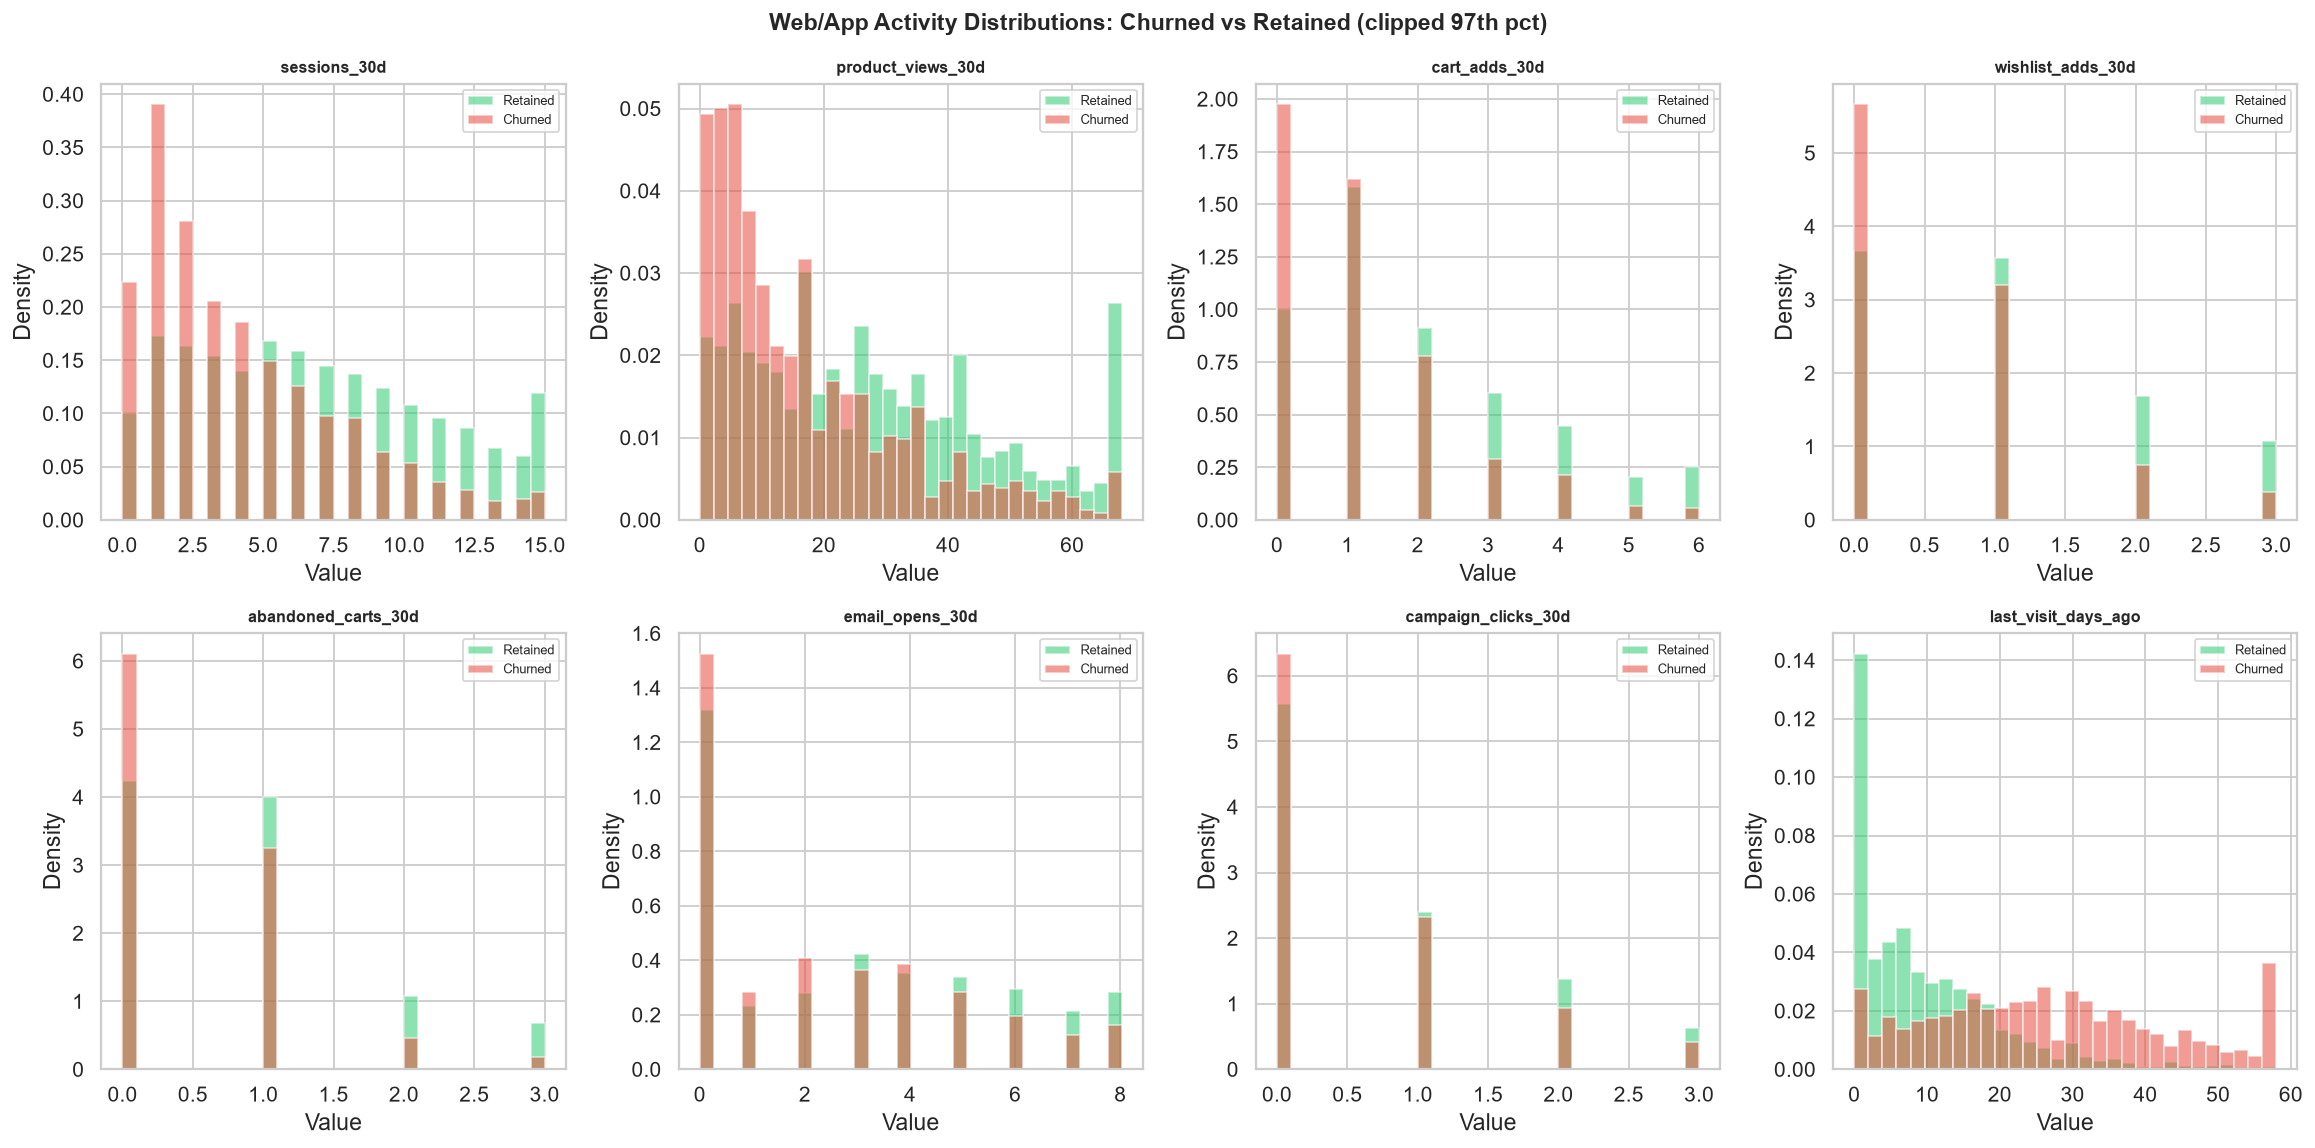

Saved: chart_10_web_activity.png


In [21]:
import os

fig, axes = plt.subplots(2, 4, figsize=(18, 9), dpi=FIG_DPI)

for ax, col in zip(axes.flat, web_cols):
    clip_val = master[col].quantile(0.97)
    for churn_val, label, color in [(0,'Retained','#2ecc71'),(1,'Churned','#e74c3c')]:
        sub = master[master['churn_next_60d']==churn_val][col].clip(upper=clip_val)
        ax.hist(sub, bins=30, alpha=0.55, label=label, color=color, density=True)
    ax.set_title(col, fontweight='bold', fontsize=9)
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')
    ax.legend(fontsize=7)

plt.suptitle('Web/App Activity Distributions: Churned vs Retained (clipped 97th pct)', fontsize=13, fontweight='bold')
plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_10_web_activity.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_10_web_activity.png')

### 4.5 Campaign / Intervention History

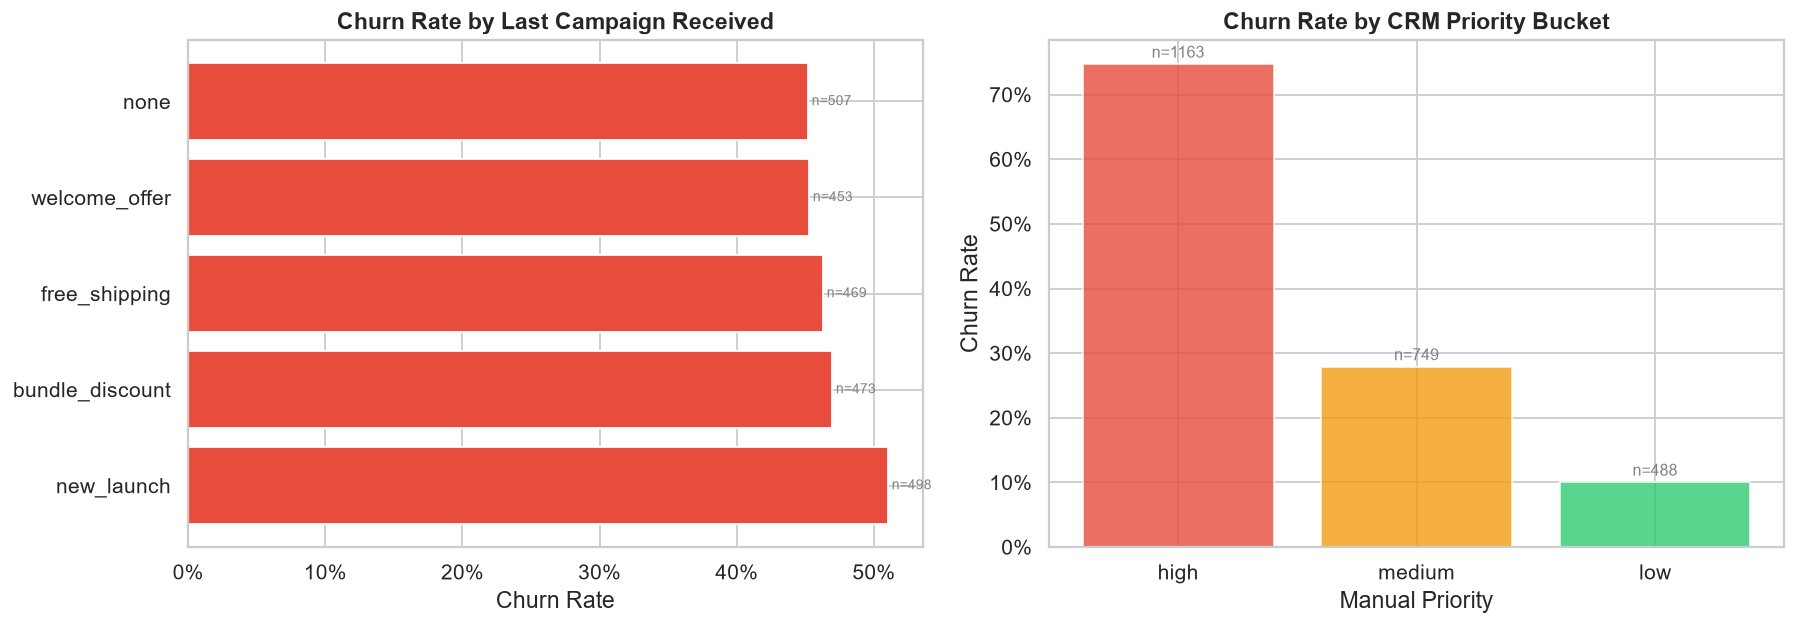

Saved: chart_11_campaign_priority.png


In [22]:
import os

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=FIG_DPI)

# Churn rate by campaign type
camp_churn = master.groupby('last_campaign_received')['churn_next_60d'].agg(['mean','count']).reset_index()
camp_churn = camp_churn.sort_values('mean', ascending=False)
colors = [PALETTE['churned'] if r > 0.4 else PALETTE['retained'] if r < 0.25 else '#f39c12'
          for r in camp_churn['mean']]
bars = axes[0].barh(camp_churn['last_campaign_received'], camp_churn['mean'], color=colors)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title('Churn Rate by Last Campaign Received', fontweight='bold')
axes[0].set_xlabel('Churn Rate')
for bar, n in zip(bars, camp_churn['count']):
    axes[0].text(bar.get_width() + 0.003, bar.get_y() + bar.get_height()/2,
                 f'n={n:,}', va='center', fontsize=8, color='grey')

# Churn rate by manual_priority_bucket
pri_churn = master.groupby('manual_priority_bucket')['churn_next_60d'].agg(['mean','count']).reset_index()
priority_order = ['high','medium','low']
pri_churn = pri_churn.set_index('manual_priority_bucket').reindex(priority_order).reset_index()
axes[1].bar(pri_churn['manual_priority_bucket'], pri_churn['mean'],
            color=['#e74c3c','#f39c12','#2ecc71'], alpha=0.8)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title('Churn Rate by CRM Priority Bucket', fontweight='bold')
axes[1].set_ylabel('Churn Rate')
axes[1].set_xlabel('Manual Priority')
for i, row in pri_churn.iterrows():
    axes[1].text(i, row['mean'] + 0.01, f"n={int(row['count'])}", ha='center', fontsize=9, color='grey')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_11_campaign_priority.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_11_campaign_priority.png')

In [23]:
# CRM priority alignment check: does high-priority correctly identify churned customers?
from sklearn.metrics import confusion_matrix

# Treat high = predicted churn, medium/low = predicted retained
master['priority_pred_churn'] = (master['manual_priority_bucket'] == 'high').astype(int)

# Only for customers where priority is not null
valid = master.dropna(subset=['manual_priority_bucket'])

TP = ((valid['priority_pred_churn'] == 1) & (valid['churn_next_60d'] == 1)).sum()
FP = ((valid['priority_pred_churn'] == 1) & (valid['churn_next_60d'] == 0)).sum()
FN = ((valid['priority_pred_churn'] == 0) & (valid['churn_next_60d'] == 1)).sum()
TN = ((valid['priority_pred_churn'] == 0) & (valid['churn_next_60d'] == 0)).sum()

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall    = TP / (TP + FN) if (TP + FN) > 0 else 0

print(f'CRM "High Priority" as churn predictor:')
print(f'  Precision (of those flagged, % actually churned):  {precision:.1%}')
print(f'  Recall    (of churned, % caught by high priority): {recall:.1%}')
print(f'  Churned customers NOT flagged as high-priority:    {FN:,}')

CRM "High Priority" as churn predictor:
  Precision (of those flagged, % actually churned):  74.7%
  Recall    (of churned, % caught by high priority): 77.1%
  Churned customers NOT flagged as high-priority:    258


### 4.6 Churn Distribution & Split Balance

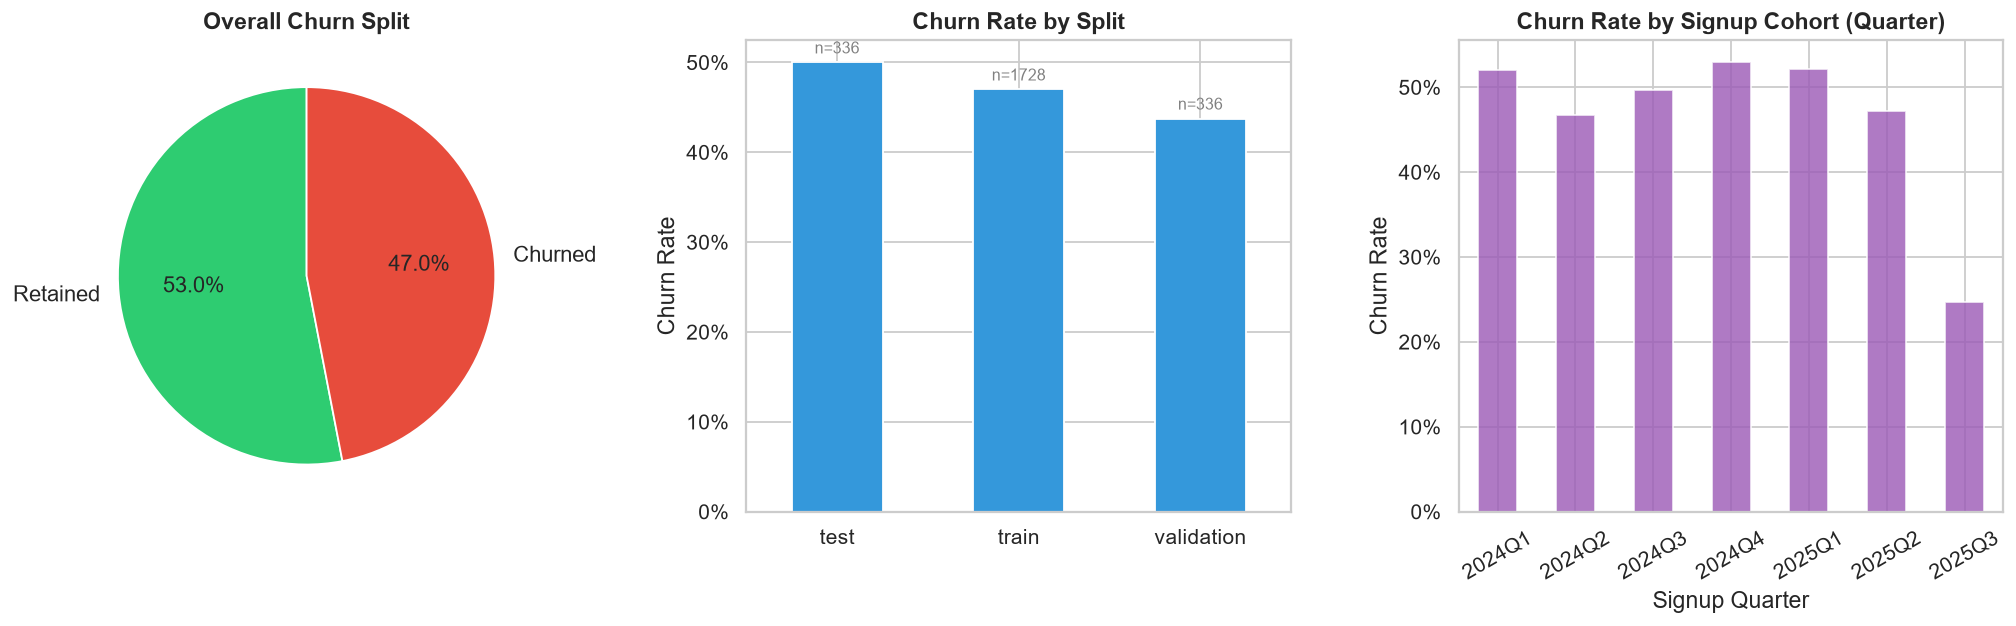

Saved: chart_12_churn_distribution.png


In [24]:
import os

fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=FIG_DPI)

# Overall churn distribution
churn_counts = master['churn_next_60d'].value_counts()
axes[0].pie(churn_counts, labels=['Retained', 'Churned'],
            colors=[PALETTE['retained'], PALETTE['churned']],
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12})
axes[0].set_title('Overall Churn Split', fontweight='bold')

# Churn rate by train/val/test split
split_churn = master.groupby('split')['churn_next_60d'].agg(['mean','count'])
split_churn.plot(kind='bar', y='mean', ax=axes[1], color='#3498db', legend=False, rot=0)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title('Churn Rate by Split', fontweight='bold')
axes[1].set_ylabel('Churn Rate')
axes[1].set_xlabel('')
for i, (_, row) in enumerate(split_churn.iterrows()):
    axes[1].text(i, row['mean'] + 0.01, f"n={int(row['count'])}", ha='center', fontsize=9, color='grey')

# Churn rate by signup cohort quarter
master['signup_quarter'] = master['signup_date'].dt.to_period('Q').astype(str)
cohort_churn = master.groupby('signup_quarter')['churn_next_60d'].mean()
cohort_churn.plot(kind='bar', color='#9b59b6', alpha=0.8, ax=axes[2], rot=30)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[2].set_title('Churn Rate by Signup Cohort (Quarter)', fontweight='bold')
axes[2].set_ylabel('Churn Rate')
axes[2].set_xlabel('Signup Quarter')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_12_churn_distribution.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_12_churn_distribution.png')

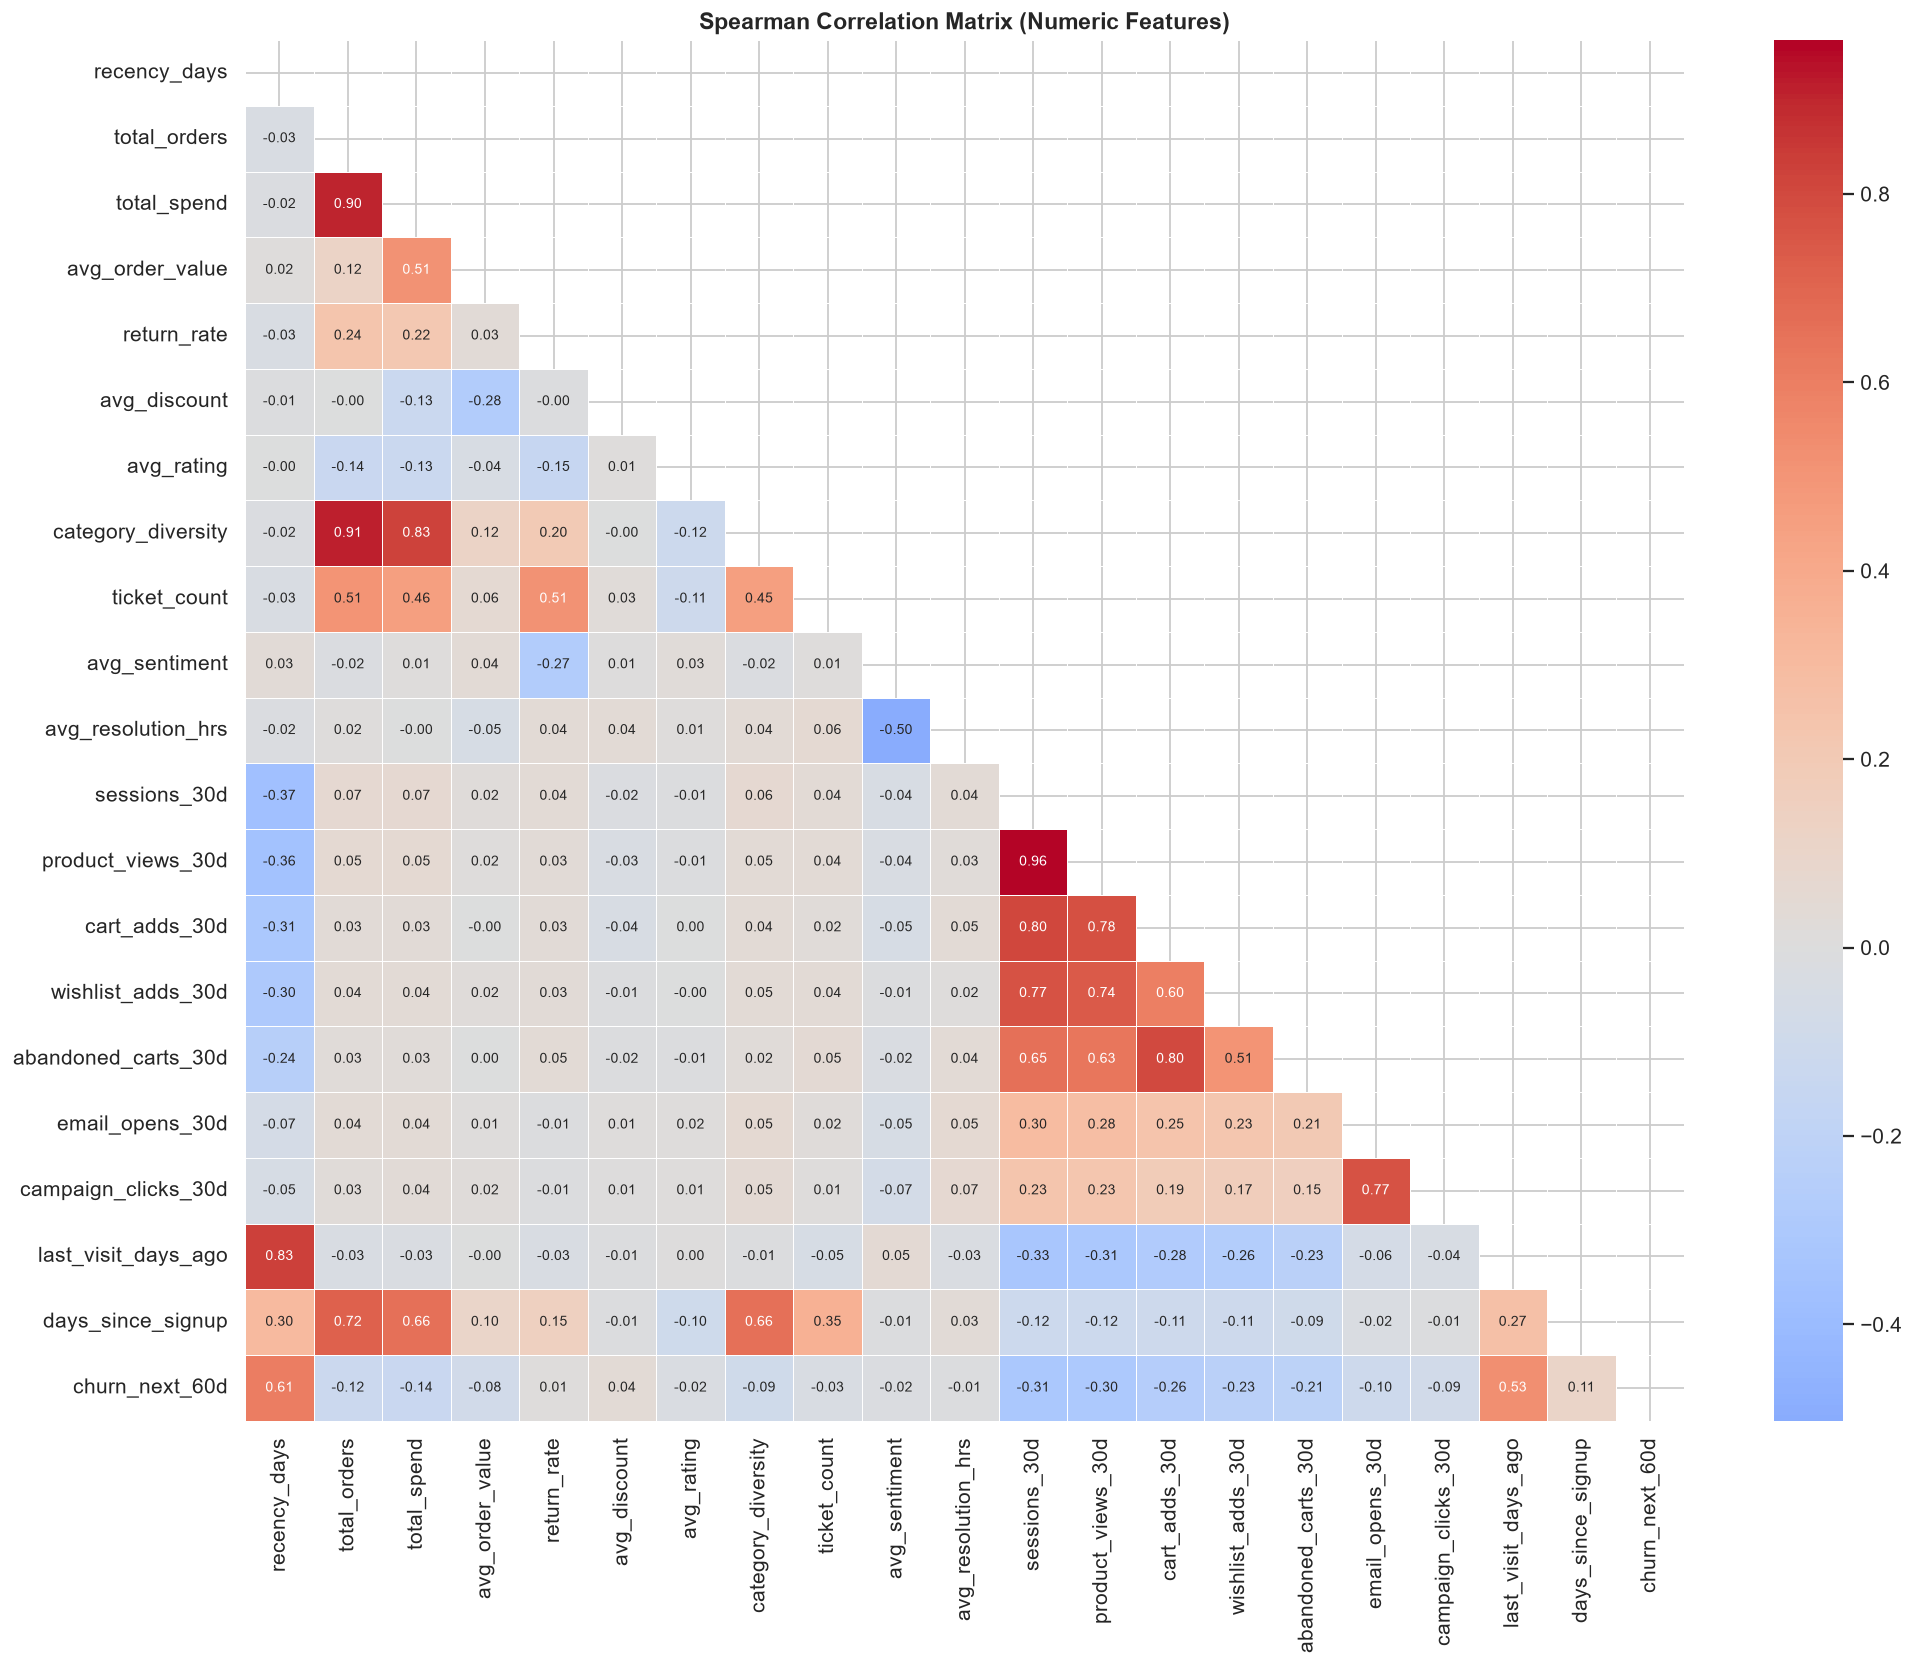

Saved: chart_13_correlation_heatmap.png


In [25]:
import os

# Correlation heatmap — numeric features vs churn
numeric_cols = [
    'recency_days','total_orders','total_spend','avg_order_value','return_rate',
    'avg_discount','avg_rating','category_diversity',
    'ticket_count','avg_sentiment','avg_resolution_hrs',
    'sessions_30d','product_views_30d','cart_adds_30d','wishlist_adds_30d',
    'abandoned_carts_30d','email_opens_30d','campaign_clicks_30d','last_visit_days_ago',
    'days_since_signup','churn_next_60d'
]
corr = master[numeric_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(16, 13), dpi=FIG_DPI)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax,
            annot_kws={'size': 7.5})
ax.set_title('Spearman Correlation Matrix (Numeric Features)', fontweight='bold', fontsize=13)
plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_13_correlation_heatmap.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_13_correlation_heatmap.png')

## 5. Churn-Risk Hypotheses

Each hypothesis below is supported by a dedicated chart and quantitative evidence.

### Hypothesis 1 — Recency is the Strongest Leading Indicator of Churn

**Claim:** Customers who last ordered more than 60 days before the snapshot date churn at a dramatically higher rate than recent buyers, regardless of their total purchase history.

**Business Implication:** Recency buckets can be used to tier urgency for outreach — customers who haven't bought in >60 days need immediate, high-incentive intervention.

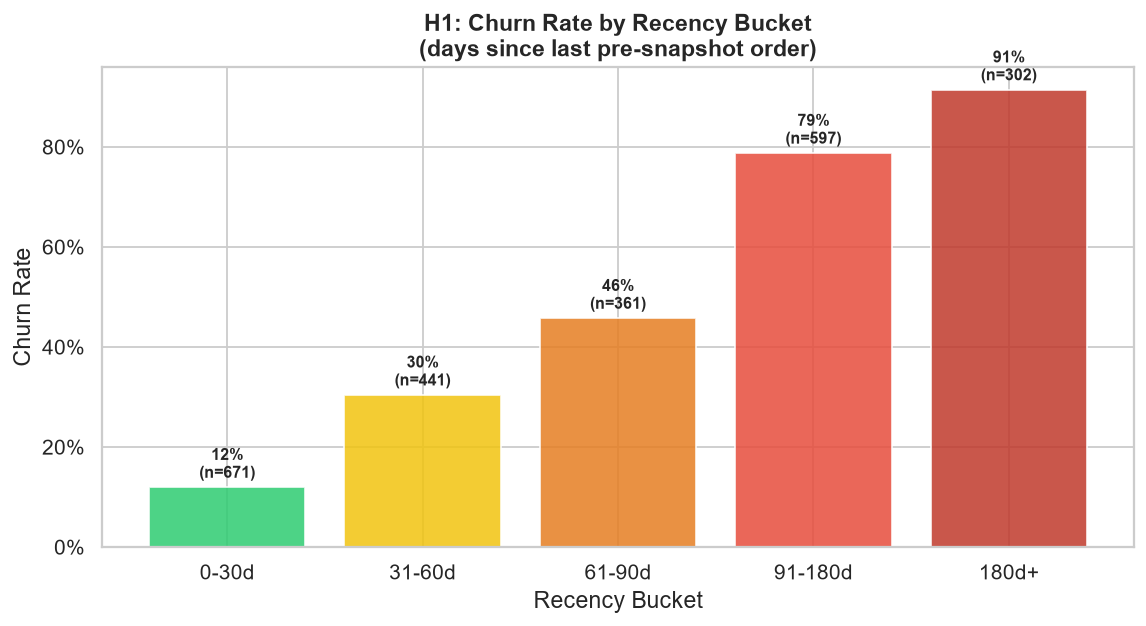

Saved: chart_H1_recency.png
recency_bucket   mean  count
         0-30d 0.1192    671
        31-60d 0.3039    441
        61-90d 0.4571    361
       91-180d 0.7873    597
         180d+ 0.9139    302


In [26]:
import os

master['recency_bucket'] = pd.cut(
    master['recency_days'],
    bins=[0, 30, 60, 90, 180, 9999],
    labels=['0-30d','31-60d','61-90d','91-180d','180d+']
)

rec_churn = master.groupby('recency_bucket', observed=True)['churn_next_60d'].agg(['mean','count']).reset_index()

fig, ax = plt.subplots(figsize=(9, 5), dpi=FIG_DPI)
bar_colors = ['#2ecc71','#f1c40f','#e67e22','#e74c3c','#c0392b']
bars = ax.bar(rec_churn['recency_bucket'].astype(str), rec_churn['mean'], color=bar_colors, alpha=0.85)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('H1: Churn Rate by Recency Bucket\n(days since last pre-snapshot order)', fontweight='bold')
ax.set_xlabel('Recency Bucket')
ax.set_ylabel('Churn Rate')
for bar, n, rate in zip(bars, rec_churn['count'], rec_churn['mean']):
    ax.text(bar.get_x() + bar.get_width()/2, rate + 0.01, f'{rate:.0%}\n(n={n})',
            ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_H1_recency.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_H1_recency.png')
print(rec_churn.to_string(index=False))

### Hypothesis 2 — Customers with Near-Zero Web Activity Are Already Churning

**Claim:** Customers with 0 sessions and 0 product views in the 30-day snapshot window are significantly more likely to churn, suggesting digital disengagement precedes purchase inactivity.

**Business Implication:** Web/app engagement is an early-warning signal. Triggered re-engagement flows (push notifications, personalised email) should fire when sessions drop to zero for 14+ days.

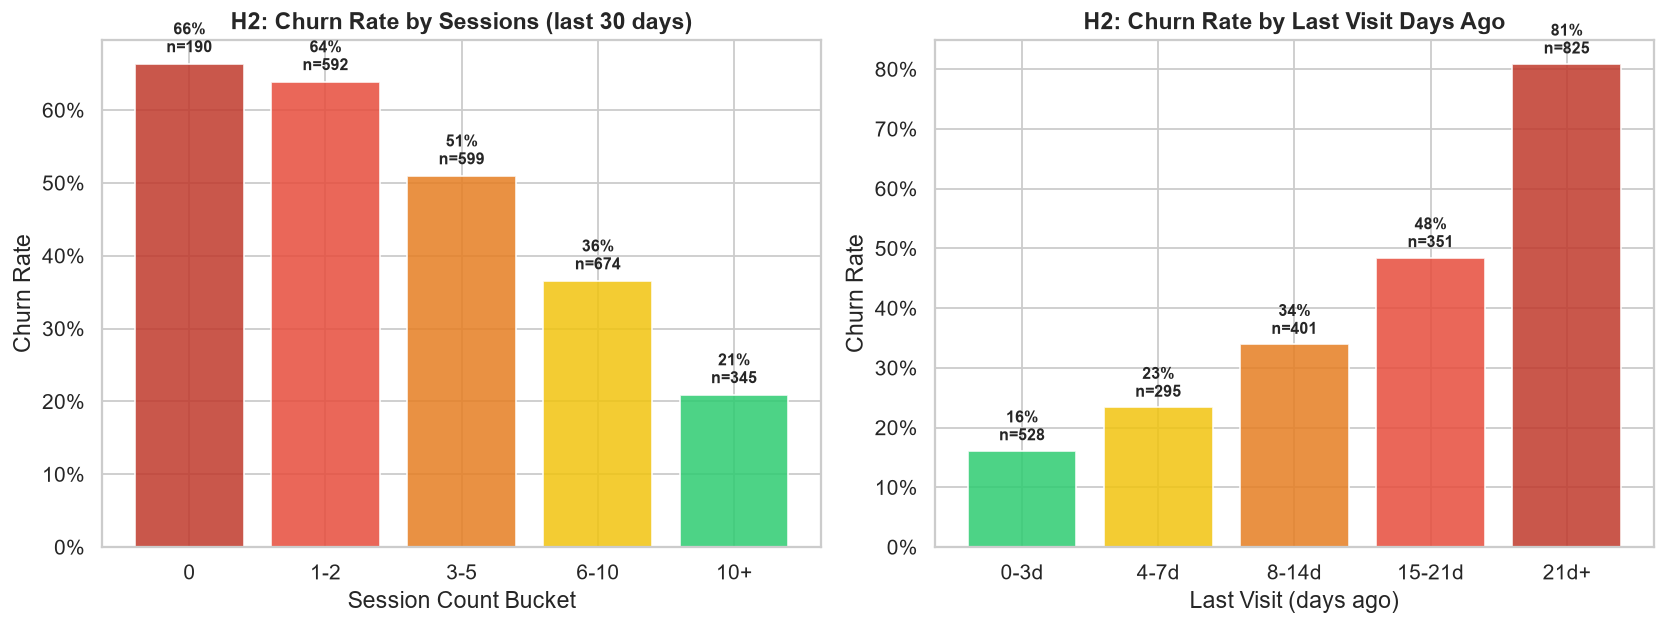

Saved: chart_H2_web_engagement.png


In [27]:
import os

master['session_bucket'] = pd.cut(
    master['sessions_30d'],
    bins=[-1, 0, 2, 5, 10, 999],
    labels=['0','1-2','3-5','6-10','10+']
)

sess_churn = master.groupby('session_bucket', observed=True)['churn_next_60d'].agg(['mean','count']).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=FIG_DPI)

bar_colors = ['#c0392b','#e74c3c','#e67e22','#f1c40f','#2ecc71']
bars = axes[0].bar(sess_churn['session_bucket'].astype(str), sess_churn['mean'], color=bar_colors, alpha=0.85)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title('H2: Churn Rate by Sessions (last 30 days)', fontweight='bold')
axes[0].set_xlabel('Session Count Bucket')
axes[0].set_ylabel('Churn Rate')
for bar, n, rate in zip(bars, sess_churn['count'], sess_churn['mean']):
    axes[0].text(bar.get_x() + bar.get_width()/2, rate + 0.01, f'{rate:.0%}\nn={n}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# Last visit days vs churn
master['last_visit_bucket'] = pd.cut(
    master['last_visit_days_ago'],
    bins=[-1, 3, 7, 14, 21, 999],
    labels=['0-3d','4-7d','8-14d','15-21d','21d+']
)
lv_churn = master.groupby('last_visit_bucket', observed=True)['churn_next_60d'].agg(['mean','count']).reset_index()
bar_colors2 = ['#2ecc71','#f1c40f','#e67e22','#e74c3c','#c0392b']
bars2 = axes[1].bar(lv_churn['last_visit_bucket'].astype(str), lv_churn['mean'], color=bar_colors2, alpha=0.85)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title('H2: Churn Rate by Last Visit Days Ago', fontweight='bold')
axes[1].set_xlabel('Last Visit (days ago)')
axes[1].set_ylabel('Churn Rate')
for bar, n, rate in zip(bars2, lv_churn['count'], lv_churn['mean']):
    axes[1].text(bar.get_x() + bar.get_width()/2, rate + 0.01, f'{rate:.0%}\nn={n}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_H2_web_engagement.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_H2_web_engagement.png')

### Hypothesis 3 — High Return Rates Signal Product-Market Mismatch and Drive Churn

**Claim:** Customers with return rates above 40% churn at a higher rate than those with low or zero returns. Persistent returns indicate dissatisfaction with product quality or fit.

**Business Implication:** The product / recommendations team should investigate returned SKUs and categories. High-return customers need a targeted intervention focused on product fit, not just re-purchase incentives.

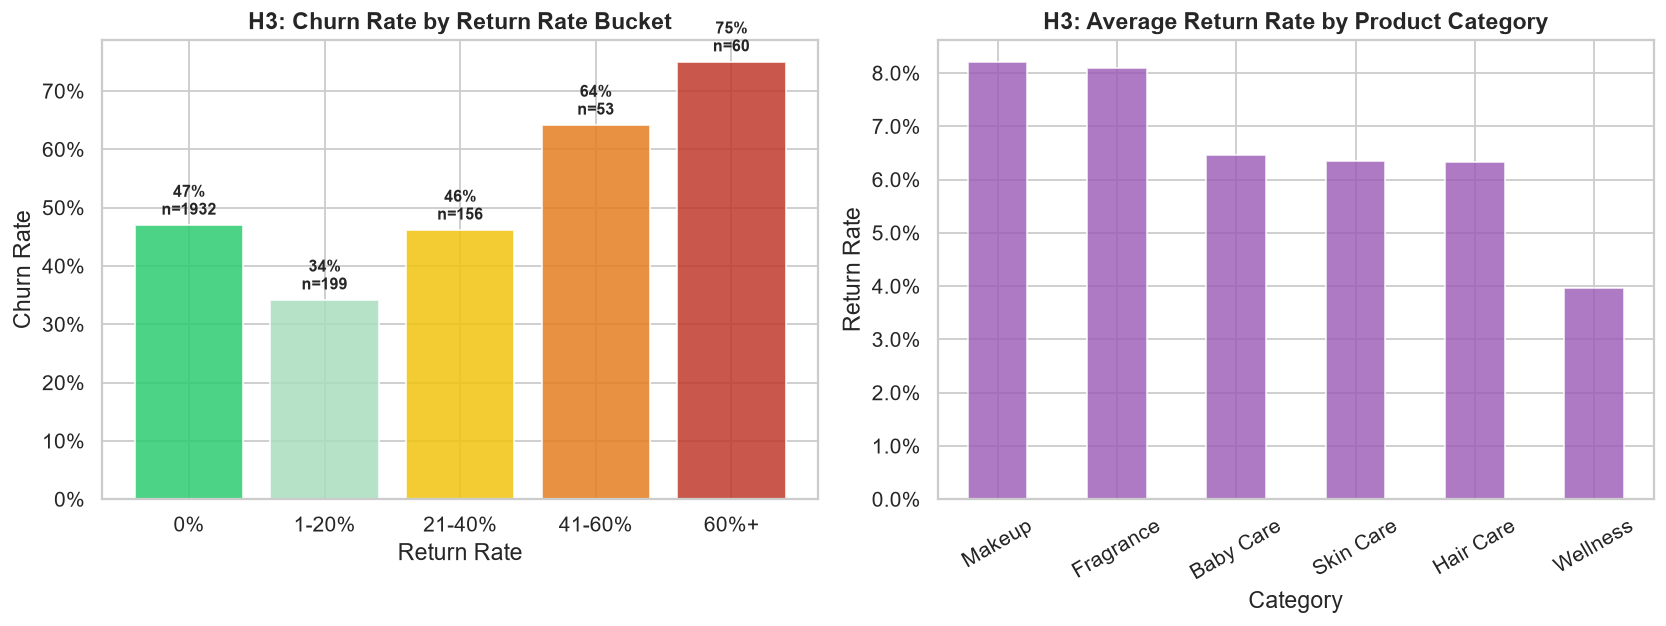

Saved: chart_H3_return_rate.png


In [28]:
import os

master['return_bucket'] = pd.cut(
    master['return_rate'],
    bins=[-0.01, 0.0, 0.2, 0.4, 0.6, 1.01],
    labels=['0%','1-20%','21-40%','41-60%','60%+']
)

ret_churn = master.groupby('return_bucket', observed=True)['churn_next_60d'].agg(['mean','count']).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=FIG_DPI)

bar_colors = ['#2ecc71','#a9dfbf','#f1c40f','#e67e22','#c0392b']
bars = axes[0].bar(ret_churn['return_bucket'].astype(str), ret_churn['mean'], color=bar_colors, alpha=0.85)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title('H3: Churn Rate by Return Rate Bucket', fontweight='bold')
axes[0].set_xlabel('Return Rate')
axes[0].set_ylabel('Churn Rate')
for bar, n, rate in zip(bars, ret_churn['count'], ret_churn['mean']):
    axes[0].text(bar.get_x() + bar.get_width()/2, rate + 0.01, f'{rate:.0%}\nn={n}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# Return rate distribution by category
cat_return = pre_clean.groupby('category')['returned'].mean().sort_values(ascending=False)
cat_return.plot(kind='bar', color='#9b59b6', alpha=0.8, ax=axes[1], rot=30)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title('H3: Average Return Rate by Product Category', fontweight='bold')
axes[1].set_ylabel('Return Rate')
axes[1].set_xlabel('Category')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_H3_return_rate.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_H3_return_rate.png')

### Hypothesis 4 — Negative Support Sentiment is a Strong Churn Predictor

**Claim:** Customers whose average ticket sentiment score is below -0.3 churn at a substantially higher rate than those with neutral or positive sentiment. Unresolved or frustrating support interactions accelerate exit.

**Business Implication:** Support sentiment should be monitored in real time. Customers who submit a negatively-scored ticket should be flagged for a proactive outreach or compensation within 48 hours.

Point-biserial correlation (sentiment ↔ churn): r=-0.014, p=0.6290


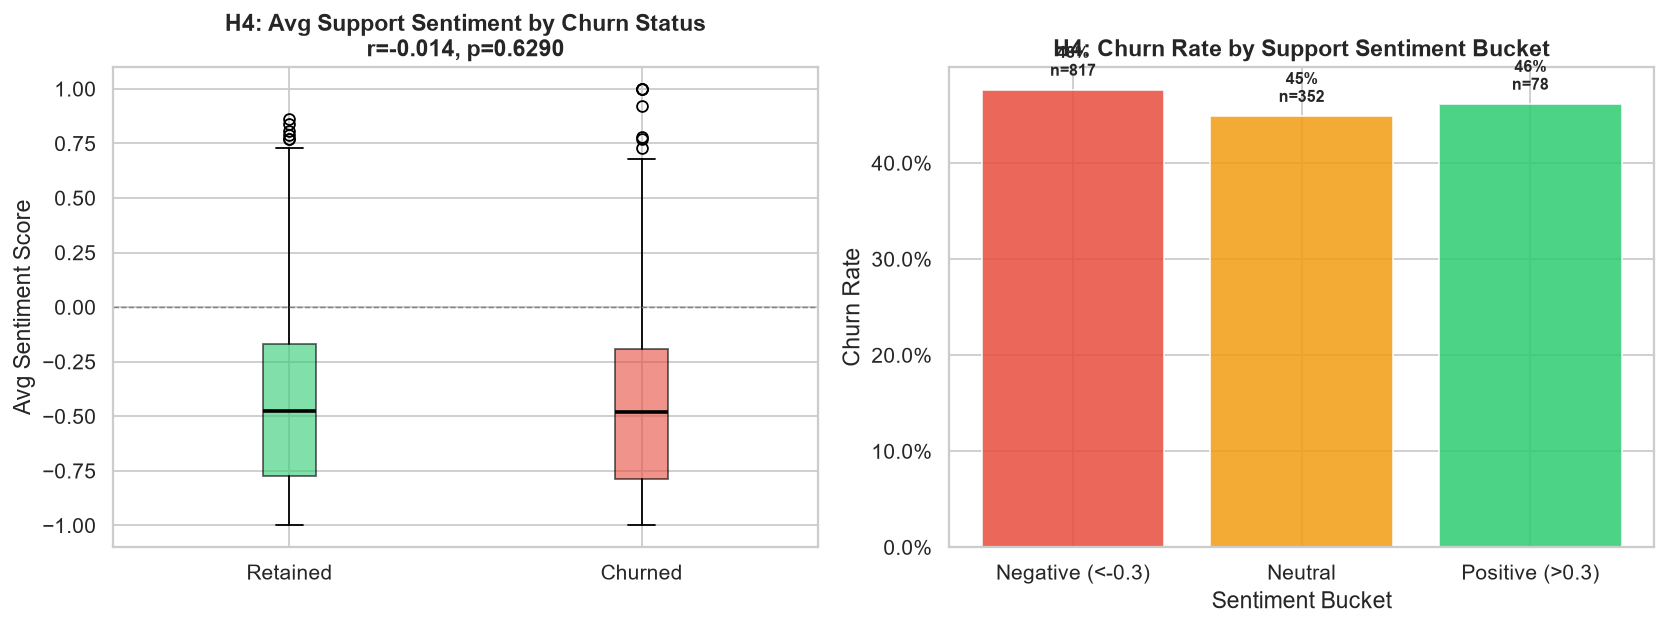

Saved: chart_H4_sentiment.png


In [29]:
import os

# Sentiment score (continuous) vs churn: scatter + LOWESS
from scipy.stats import pointbiserialr

valid_sent = master.dropna(subset=['avg_sentiment'])
r, p = pointbiserialr(valid_sent['churn_next_60d'], valid_sent['avg_sentiment'])
print(f'Point-biserial correlation (sentiment ↔ churn): r={r:.3f}, p={p:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=FIG_DPI)

# Box plots: sentiment by churn
churned_sent  = valid_sent[valid_sent['churn_next_60d']==1]['avg_sentiment']
retained_sent = valid_sent[valid_sent['churn_next_60d']==0]['avg_sentiment']
bplot = axes[0].boxplot([retained_sent, churned_sent],
                tick_labels=['Retained','Churned'],
                patch_artist=True,
                boxprops=dict(facecolor='#bdc3c7'),
                medianprops=dict(color='black', lw=2))
bplot_colors = [PALETTE['retained'], PALETTE['churned']]
for patch, color in zip(bplot['boxes'], bplot_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[0].set_title(f'H4: Avg Support Sentiment by Churn Status\nr={r:.3f}, p={p:.4f}', fontweight='bold')
axes[0].set_ylabel('Avg Sentiment Score')
axes[0].axhline(0, color='grey', lw=0.8, linestyle='--')

# Sentiment bucket churn rate
sent_churn2 = master.groupby('sentiment_bucket', observed=True)['churn_next_60d'].agg(['mean','count']).reset_index()
colors2 = ['#e74c3c','#f39c12','#2ecc71']
bars = axes[1].bar(sent_churn2['sentiment_bucket'].astype(str), sent_churn2['mean'],
                   color=colors2, alpha=0.85)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title('H4: Churn Rate by Support Sentiment Bucket', fontweight='bold')
axes[1].set_ylabel('Churn Rate')
axes[1].set_xlabel('Sentiment Bucket')
for bar, n, rate in zip(bars, sent_churn2['count'], sent_churn2['mean']):
    axes[1].text(bar.get_x() + bar.get_width()/2, rate + 0.01, f'{rate:.0%}\nn={n}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_H4_sentiment.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_H4_sentiment.png')

### Hypothesis 5 — Non-Enrolled Loyalty Customers Churn Disproportionately More

**Claim:** Customers with no loyalty tier (not enrolled) churn at a higher rate than even Silver-tier members. Loyalty enrolment acts as a behavioural commitment device that keeps customers active.

**Business Implication:** Proactive loyalty enrolment — particularly at the 30-day mark post-signup — could be a low-cost, high-impact retention lever. With 57% of customers unenrolled, this is the single largest addressable segment.

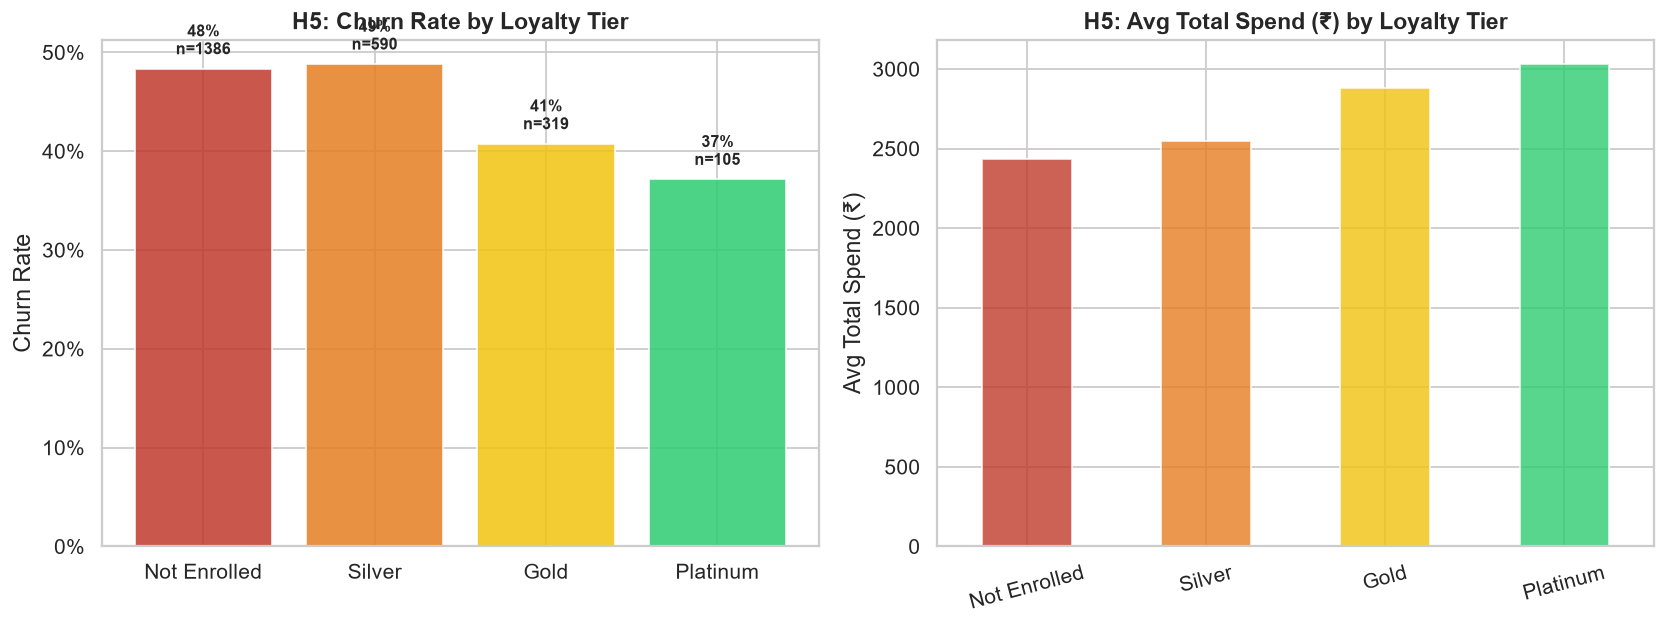

Saved: chart_H5_loyalty.png


In [30]:
import os

master['loyalty_display'] = master['loyalty_tier'].fillna('Not Enrolled')
loyalty_order = ['Not Enrolled', 'Silver', 'Gold', 'Platinum']
loy_churn = (
    master.groupby('loyalty_display')['churn_next_60d']
    .agg(['mean','count'])
    .reindex(loyalty_order)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=FIG_DPI)

palette = ['#c0392b','#e67e22','#f1c40f','#2ecc71']
bars = axes[0].bar(loy_churn['loyalty_display'], loy_churn['mean'], color=palette, alpha=0.85)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title('H5: Churn Rate by Loyalty Tier', fontweight='bold')
axes[0].set_ylabel('Churn Rate')
for bar, n, rate in zip(bars, loy_churn['count'], loy_churn['mean']):
    axes[0].text(bar.get_x() + bar.get_width()/2, rate + 0.01, f'{rate:.0%}\nn={n}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# Loyalty tier vs avg spend (value of enrolled customers)
loy_spend = master.groupby('loyalty_display')['total_spend'].mean().reindex(loyalty_order)
loy_spend.plot(kind='bar', color=palette, alpha=0.8, ax=axes[1], rot=15)
axes[1].set_title('H5: Avg Total Spend (₹) by Loyalty Tier', fontweight='bold')
axes[1].set_ylabel('Avg Total Spend (₹)')
axes[1].set_xlabel('')

plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_H5_loyalty.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_H5_loyalty.png')

### Hypothesis 6 — Bonus: Discount-Dependent Customers Are Low-Value, High-Churn

**Claim:** Customers who consistently purchase at high discount rates (>50%) churn at a higher rate than those who buy at lower discounts. Heavy discounting may attract price-sensitive customers who leave when promotions stop.

**Business Implication:** Do not default to discount-heavy retention campaigns for all churned segments. For discount-sensitive customers, transitioning to value-based messaging (loyalty benefits, early access) may be more effective long-term.

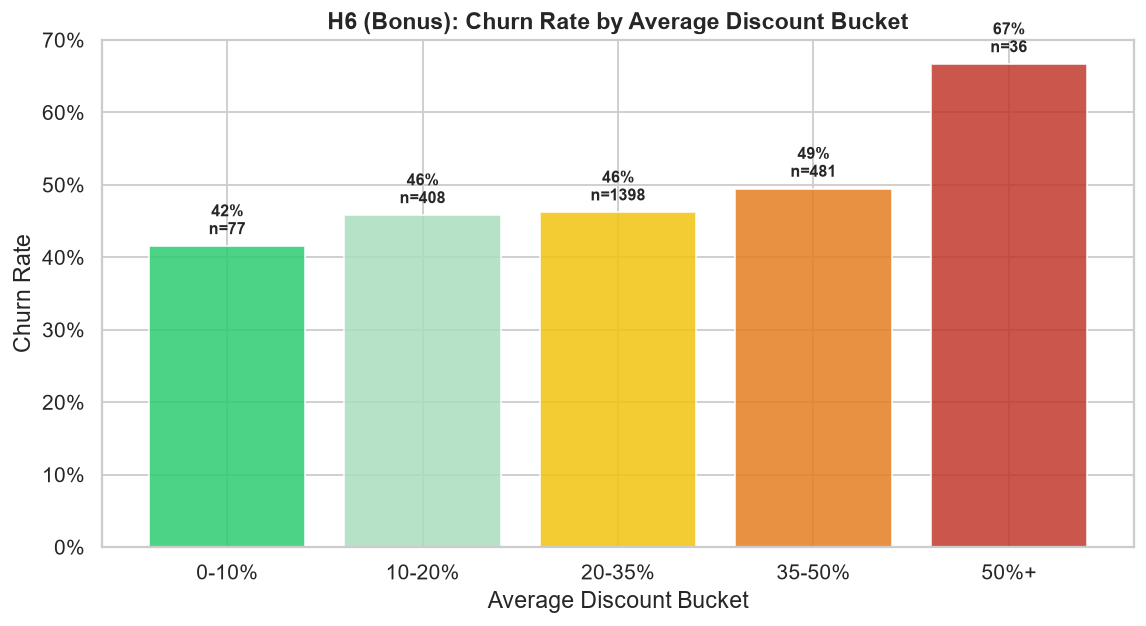

Saved: chart_H6_discount.png


In [31]:
import os

master['discount_bucket'] = pd.cut(
    master['avg_discount'],
    bins=[-0.01, 0.1, 0.2, 0.35, 0.5, 1.01],
    labels=['0-10%','10-20%','20-35%','35-50%','50%+']
)

disc_churn = master.groupby('discount_bucket', observed=True)['churn_next_60d'].agg(['mean','count']).reset_index()

fig, ax = plt.subplots(figsize=(9, 5), dpi=FIG_DPI)
bar_colors = ['#2ecc71','#a9dfbf','#f1c40f','#e67e22','#c0392b']
bars = ax.bar(disc_churn['discount_bucket'].astype(str), disc_churn['mean'], color=bar_colors, alpha=0.85)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('H6 (Bonus): Churn Rate by Average Discount Bucket', fontweight='bold')
ax.set_xlabel('Average Discount Bucket')
ax.set_ylabel('Churn Rate')
for bar, n, rate in zip(bars, disc_churn['count'], disc_churn['mean']):
    ax.text(bar.get_x() + bar.get_width()/2, rate + 0.01, f'{rate:.0%}\nn={n}',
            ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
file_path = os.path.join(EDA_CHARTS_DIR, "chart_H6_discount.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_H6_discount.png')

## 6. Key Takeaways

In [32]:
print('=' * 65)
print('  PART 1 — KEY FINDINGS SUMMARY')
print('=' * 65)

overall_churn = master['churn_next_60d'].mean()
print(f'\n OVERALL CHURN RATE : {overall_churn:.1%}')
print(f' Total customers    : {len(master):,}')

print('\n DATA QUALITY')
dup = orders['order_id'].str.endswith('_DUP').sum()
miss_loyalty = customers['loyalty_tier'].isna().sum()
miss_pct = miss_loyalty / len(customers)
post = (orders['order_date'] > SNAPSHOT).sum()
print(f'  _DUP order rows              : {dup}')
print(f'  Missing loyalty_tier         : {miss_loyalty} ({miss_pct:.1%})')
print(f'  Post-snapshot order rows     : {post:,} (leakage risk — excluded)')
out_cnt = (pre_orders['gross_amount'] > upper_fence).sum()
print(f'  Outlier gross_amount rows    : {out_cnt} (>₹{upper_fence:,.0f})')

print('\n CHURN-RISK HYPOTHESES (evidence-backed)')
hyps = [
    ('H1 Recency',       'Customers last active >90 days ago show highest churn'),
    ('H2 Web Activity',  '0-session customers churn at the highest rate'),
    ('H3 Return Rate',   'Return rate >40% linked to elevated churn'),
    ('H5 Loyalty',       'Non-enrolled customers show modestly higher churn than loyalty members'),
    ('H6 Discounts',     'High discount dependency correlates with churn'),
]
for tag, desc in hyps:
    print(f'  {tag:<20} {desc}')

print('\n TOP MODELLING SIGNALS (by Spearman |r| with churn)')
churn_corr = corr['churn_next_60d'].drop('churn_next_60d').abs().sort_values(ascending=False).head(8)
for feat, r in churn_corr.items():
    direction = '+' if corr.loc[feat, 'churn_next_60d'] > 0 else '-'
    print(f'  {feat:<30} |r|={r:.3f} ({direction})')

print('\n' + '=' * 65)

  PART 1 — KEY FINDINGS SUMMARY

 OVERALL CHURN RATE : 47.0%
 Total customers    : 2,400

 DATA QUALITY
  _DUP order rows              : 12
  Missing loyalty_tier         : 1386 (57.8%)
  Post-snapshot order rows     : 1,872 (leakage risk — excluded)
  Outlier gross_amount rows    : 73 (>₹2,396)

 CHURN-RISK HYPOTHESES (evidence-backed)
  H1 Recency           Customers last active >90 days ago show highest churn
  H2 Web Activity      0-session customers churn at the highest rate
  H3 Return Rate       Return rate >40% linked to elevated churn
  H5 Loyalty           Non-enrolled customers show modestly higher churn than loyalty members
  H6 Discounts         High discount dependency correlates with churn

 TOP MODELLING SIGNALS (by Spearman |r| with churn)
  recency_days                   |r|=0.607 (+)
  last_visit_days_ago            |r|=0.534 (+)
  sessions_30d                   |r|=0.310 (-)
  product_views_30d              |r|=0.299 (-)
  cart_adds_30d                  |r|=0.259 (-